# Understanding a Graph Through Its Spectrum

A graph records *who is connected to whom* and nothing else. This lesson shows that this bare
connectivity information, once written as a matrix and decomposed into eigenvalues and
eigenvectors, already tells us a great deal: whether the graph is in one piece, where it is
fragile, and which groups of nodes hang together.

**Who this is for.** You are comfortable with Python and with linear algebra (matrices,
eigenvalues, orthonormal bases). You have not worked with spectral graph theory before.

**Scope.** Static, undirected, unweighted graphs. We do not cover measured node signals,
time-varying graphs, or graph neural networks.

### The one distinction to keep straight

Two ideas are easy to confuse, so we separate them now and return to it in Section 3.

| | **The spectrum of a graph** (this lesson) | **The graph Fourier transform of a signal** (next lesson) |
|---|---|---|
| What you need | A graph $G=(V,E)$ | A graph **and** a measured value at each node |
| What you compute | Eigenvalues $\lambda_k$ and eigenvectors $u_k$ of a matrix built from $E$ | Coefficients $\hat{x}_k = u_k^\top x$ of a data vector $x$ |
| What it describes | The domain itself — its shape, its bottlenecks | Data living *on* that domain |

An analogy: on the real line, the sinusoids $e^{i\omega t}$ are fixed by the domain before any
data arrives; the Fourier transform of a function is what you get by projecting *that function*
onto them. The graph spectrum plays the role of the sinusoids and their frequencies. Everything
we plot in this lesson is a property of the graph, never a measurement.

### Roadmap

1. A real graph and the question we want to answer
2. From connectivity to matrices: $A$, $D$, $L$
3. Eigenvalues and eigenvectors, and what "frequency" means on a graph
4. Connectivity, bottlenecks, and the Fiedler vector
5. Spectral embedding, and which matrix to use
6. Recap, interpretation questions, and correctness checks

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Deterministic output: the layout and the clustering in Section 5 are both seeded.
SEED = 7
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.constrained_layout.use": True,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
})

import scipy, matplotlib, sklearn
for name, mod in [("numpy", np), ("scipy", scipy), ("networkx", nx),
                  ("matplotlib", matplotlib), ("scikit-learn", sklearn)]:
    print(f"{name:<13} {mod.__version__}")

numpy         2.5.3
scipy         1.18.1
networkx      3.6.1
matplotlib    3.11.1
scikit-learn  1.9.1


---
## 1. A real graph and a real question

**Zachary's Karate Club.** In the early 1970s, anthropologist Wayne Zachary spent two years
observing a university karate club of 34 members, recording which pairs interacted regularly
*outside* club activities — in classes, bars, tournaments, and private lessons. During the
study a dispute between the instructor (**Mr. Hi**, node 0) and the club president
(**Officer**, node 33) split the club in two, and every member ended up in one of the two
resulting groups.

That gives us an unusually clean test:

- The **edges** are observed social contact, recorded *before* the split.
- The **split** is a separate historical fact, recorded afterwards.

So we can ask: *does the structure of the contact network, by itself, predict how the club broke
apart?* We will answer using only the edges, and use the recorded split **only at the end, to
score the answer** — never as an input.

> 📖 **Reference — the dataset.**
> [`networkx.karate_club_graph()` documentation](https://networkx.org/documentation/stable/reference/generated/networkx.generators.social.karate_club_graph.html).
> Read it for what the nodes and edges actually represent, and for the citation to Zachary's
> original 1977 paper. The thing to take away: an edge means *observed interaction*, not
> friendship self-reported on a survey — which is what makes the result below interpretable.

In [2]:
G = nx.karate_club_graph()

# A FIXED node ordering, used for every matrix and every vector in this notebook.
# Row i and column i of every matrix, and entry i of every vector, always mean nodelist[i].
nodelist = sorted(G.nodes())
n = len(nodelist)

# NetworkX ships this graph with integer edge weights (Zachary's interaction counts).
# This lesson is about UNWEIGHTED graphs, so we discard them everywhere by passing
# weight=None. Without that argument every matrix below would silently be the weighted one.
print("edge attributes present:", sorted({k for _, _, dd in G.edges(data=True) for k in dd}))
print("example weighted edge  :", list(G.edges(data=True))[0])
print()

print(f"nodes                  : {n}")
print(f"edges                  : {G.number_of_edges()}")
print(f"connected components   : {nx.number_connected_components(G)}")
print(f"self-loops             : {nx.number_of_selfloops(G)}")
print(f"density                : {nx.density(G):.3f}")

degrees = dict(G.degree())        # unweighted degree = number of distinct neighbours
print(f"degree min / mean / max: {min(degrees.values())} / "
      f"{np.mean(list(degrees.values())):.2f} / {max(degrees.values())}")

edge attributes present: ['weight']
example weighted edge  : (0, 1, {'weight': 4})

nodes                  : 34
edges                  : 78
connected components   : 1
self-loops             : 0
density                : 0.139
degree min / mean / max: 1 / 4.59 / 17


The graph is **connected** (one component) and **simple** (no self-loops, no multi-edges).
Degrees are very uneven: one member has a single contact, while the two central figures have
16 and 17. That imbalance returns in Section 5.

Now we draw it. The two colours are the **recorded historical split**, shown here only so you
can see the structure we are trying to recover. No code before Section 4's evaluation reads
these labels.

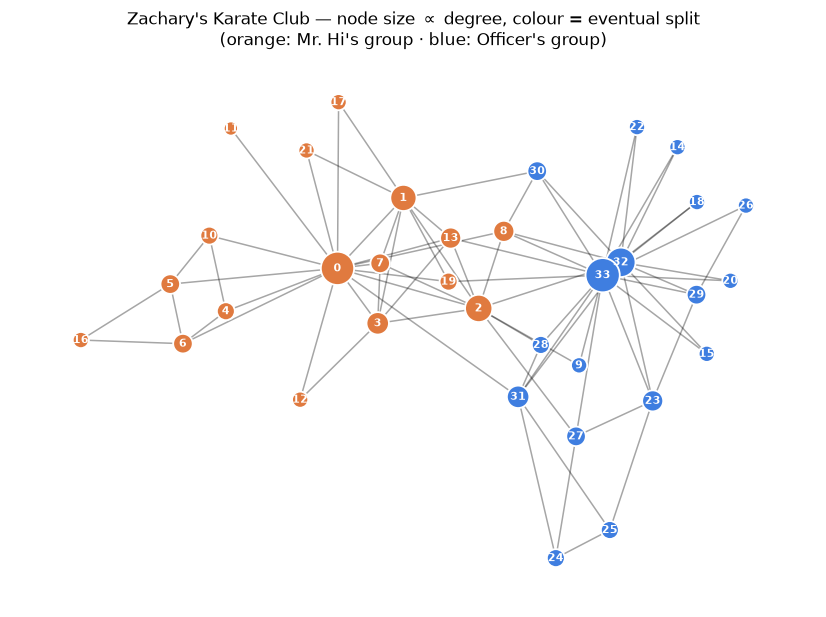

Mr. Hi's group : 17 members
Officer's group: 17 members


In [3]:
# Node coordinates for drawing. A spring layout places connected nodes near each other by
# minimising a physical-looking energy -- but the graph has NO geometry: it is a set of nodes
# and a set of pairs, nothing more. These coordinates are a VISUALISATION CHOICE. A different
# seed, or a different layout algorithm, draws the same graph differently. So never read
# distance, angle, or area in these pictures as if it meant something. Every claim we make is
# computed from the matrices, not measured off the plot.
pos = nx.spring_layout(G, seed=SEED, weight=None)

club = {v: G.nodes[v]["club"] for v in nodelist}       # 'Mr. Hi' or 'Officer'
colours = ["#e07a3f" if club[v] == "Mr. Hi" else "#3f7ee0" for v in nodelist]

fig, ax = plt.subplots(figsize=(7.4, 5.5))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=1.0)
nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=nodelist, node_color=colours,
                       node_size=[60 + 26 * degrees[v] for v in nodelist],
                       edgecolors="white", linewidths=1.2)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=7.5, font_color="white", font_weight="bold")
ax.set_title("Zachary's Karate Club — node size $\\propto$ degree, colour = eventual split\n"
             "(orange: Mr. Hi's group · blue: Officer's group)")
ax.set_axis_off()
ax.grid(False)
plt.show()

n_hi = sum(1 for v in nodelist if club[v] == "Mr. Hi")
print(f"Mr. Hi's group : {n_hi} members")
print(f"Officer's group: {n - n_hi} members")

Two dense neighbourhoods are visible, one around node 0 and one around node 33, joined by a thin
set of edges. The colours confirm that the split followed roughly that seam. Our goal is to find
the seam **from the edges alone**.

---
## 2. From connectivity to matrices

To use linear algebra we need the graph as a matrix. Fix the ordering $V=\{v_1,\dots,v_n\}$
given by `nodelist`; index $i$ always refers to node $v_i$.

**Adjacency matrix** $A \in \{0,1\}^{n\times n}$ — who is connected to whom:

$$A_{ij} \;=\; \mathbf{1}_{\{i,j\}\in E} \;=\; \begin{cases}1 & \text{if } \{v_i,v_j\}\in E,\\ 0 & \text{otherwise.}\end{cases}$$

Because the graph is undirected, $A=A^\top$; because it is simple, $A_{ii}=0$.

**Degree** $d_i$ — the number of neighbours of node $i$, which for a 0/1 matrix is just a row sum:

$$d_i \;=\; \sum_{j=1}^{n} A_{ij}.$$

**Degree matrix** $D$ — the degrees on the diagonal, zeros elsewhere:

$$D \;=\; \operatorname{diag}(d_1,\dots,d_n).$$

**Graph Laplacian** $L$ — the object this lesson is about:

$$L \;=\; D - A, \qquad\text{entrywise}\qquad
L_{ij}=\begin{cases} d_i & i=j, \\ -1 & \{v_i,v_j\}\in E, \\ 0 & \text{otherwise.}\end{cases}$$

Symbols used: $n$ is the number of nodes, $E$ the edge set, $\mathbf{1}_{(\cdot)}$ the indicator
(1 when the condition holds, else 0), and $\operatorname{diag}(\cdot)$ builds a diagonal matrix
from a list of numbers. $L$ is real and symmetric — the property that makes all of Section 3 work.

In [4]:
# Build A explicitly from the graph, with the fixed ordering and the weights discarded.
A = nx.to_numpy_array(G, nodelist=nodelist, weight=None)

d = A.sum(axis=1)         # degree vector: d[i] = number of neighbours of nodelist[i]
D = np.diag(d)            # degree matrix
L = D - A                 # combinatorial graph Laplacian

print("A shape:", A.shape, " distinct entries:", np.unique(A))
print("A symmetric:", np.allclose(A, A.T), " | zero diagonal:", np.allclose(np.diag(A), 0))
print("L symmetric:", np.allclose(L, L.T))
print("degrees match NetworkX:",
      np.array_equal(d, np.array([degrees[v] for v in nodelist], dtype=float)))

A shape: (34, 34)  distinct entries: [0. 1.]
A symmetric: True  | zero diagonal: True
L symmetric: True
degrees match NetworkX: True


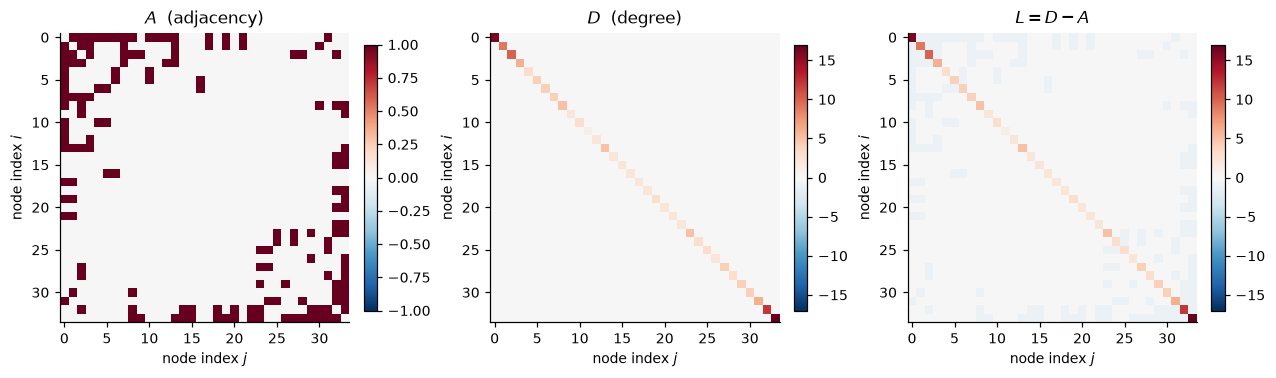

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9))
for ax, M, name in zip(axes, [A, D, L], ["$A$  (adjacency)", "$D$  (degree)", "$L = D - A$"]):
    lim = np.abs(M).max()
    im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(name)
    ax.set_xlabel("node index $j$")
    ax.set_ylabel("node index $i$")
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.show()

Read these as pictures of the graph. $A$ is sparse and symmetric, with a visibly denser block at
low indices (Mr. Hi's circle) and another at high indices. $D$ has entries only on the diagonal —
the two strongest are the hubs, nodes 0 and 33. $L$ combines them: a **positive** degree on the
diagonal and a $-1$ wherever there is an edge.

Look at a single row to see what $L$ encodes.

In [6]:
i = 5                                    # inspect the row belonging to node 5
print(f"Node {nodelist[i]} has degree d_{i} = {int(d[i])}, "
      f"neighbours {[nodelist[j] for j in np.flatnonzero(A[i] > 0)]}")
print()
print(f"Row {i} of L, non-zero entries only:")
for j in np.flatnonzero(L[i] != 0):
    kind = "diagonal  (= degree d_i)" if j == i else f"edge to node {nodelist[j]}"
    print(f"   L[{i},{j:2d}] = {L[i, j]:+.0f}    {kind}")
print()
print(f"Row sum: {L[i].sum():+.0f}   <- the degree on the diagonal exactly cancels the -1s")

Node 5 has degree d_5 = 4, neighbours [0, 6, 10, 16]

Row 5 of L, non-zero entries only:
   L[5, 0] = -1    edge to node 0
   L[5, 5] = +4    diagonal  (= degree d_i)
   L[5, 6] = -1    edge to node 6
   L[5,10] = -1    edge to node 10
   L[5,16] = -1    edge to node 16

Row sum: +0   <- the degree on the diagonal exactly cancels the -1s


Every row of $L$ sums to zero, because the diagonal entry $d_i$ counts exactly as many
neighbours as there are $-1$ entries in the row. Writing $\mathbf{1}=(1,1,\dots,1)^\top$ for
the all-ones vector:

$$L\mathbf{1} = 0.$$

That is already our first eigenvalue: $\mathbf{1}$ is an eigenvector of $L$ with eigenvalue $0$.
It is also why $L$ behaves like a *difference* operator. For any vector $q\in\mathbb{R}^n$,

$$(Lq)_i \;=\; d_i q_i - \!\!\sum_{j:\{i,j\}\in E}\!\! q_j \;=\; \sum_{j:\{i,j\}\in E} (q_i - q_j),$$

so $(Lq)_i$ measures how far $q_i$ sits from its neighbours' values. A vector that is constant
across every edge is annihilated by $L$; a vector that swings between neighbours produces a large
response. Hold on to that — it is the entire intuition for Section 3.

In [7]:
print("L @ 1 == 0 :", np.allclose(L @ np.ones(n), 0))

# The difference-operator identity, checked on an arbitrary test vector.
q_demo = rng.standard_normal(n)
by_matrix = L @ q_demo
by_edges = np.array([sum(q_demo[i] - q_demo[j] for j in np.flatnonzero(A[i] > 0))
                     for i in range(n)])
print("(Lq)_i == sum over neighbours of (q_i - q_j) :", np.allclose(by_matrix, by_edges))

L @ 1 == 0 : True
(Lq)_i == sum over neighbours of (q_i - q_j) : True


---
## 3. Eigenvalues and eigenvectors

A vector $u_k \in \mathbb{R}^n$ and a number $\lambda_k \in \mathbb{R}$ form an
**eigenpair** of $L$ when

$$L u_k = \lambda_k u_k .$$

In words: applying $L$ to $u_k$ does not change its direction, only its length, by the factor
$\lambda_k$. Since $L$ is real and symmetric, the **spectral theorem** guarantees a great deal
more than existence:

$$L \;=\; U \Lambda U^\top, \qquad U^\top U = U U^\top = I .$$

Here $U = [\,u_1 \; u_2 \; \cdots \; u_n\,] \in \mathbb{R}^{n \times n}$ has the eigenvectors as
its columns, $\Lambda = \operatorname{diag}(\lambda_1,\dots,\lambda_n)$ holds the eigenvalues,
and $I$ is the $n\times n$ identity. The condition $U^\top U = I$ says the columns are
**orthonormal**: $u_j^\top u_k = 1$ if $j=k$ and $0$ otherwise. So the eigenvectors are a
rotated coordinate system for $\mathbb{R}^n$ — a basis built by the graph, out of the graph.

We always sort **increasingly**, $\lambda_1 \le \lambda_2 \le \cdots \le \lambda_n$, and index
from $k=1$. The full list $\{\lambda_1,\dots,\lambda_n\}$ is the **spectrum** of the graph.

We use `numpy.linalg.eigh` — the `h` is for *Hermitian* (symmetric, in the real case). It
exploits the symmetry to return real eigenvalues, already sorted ascending, with numerically
orthonormal eigenvectors. Using the general-purpose `numpy.linalg.eig` here would be a mistake:
it ignores the symmetry and can return complex values with tiny imaginary parts.

In [8]:
lam, U = np.linalg.eigh(L)        # eigh: symmetric solver; eigenvalues returned ascending

# eigh already sorts ascending, but we make the ordering explicit rather than assumed.
order = np.argsort(lam)
lam, U = lam[order], U[:, order]

print("eigenvalues already ascending from eigh:", np.all(np.diff(lam) >= -1e-12))
print()
print("index k :  lambda_k")
for k in [0, 1, 2, 3, 4, 16, 17, 30, 31, 32, 33]:
    tag = ""
    if k == 0:
        tag = "   <- always 0 for any graph (eigenvector 1)"
    elif k == 1:
        tag = "   <- algebraic connectivity, Section 4"
    elif k == 33:
        tag = "   <- largest"
    print(f"   {k:2d}   : {lam[k]: .6f}{tag}")

eigenvalues already ascending from eigh: True

index k :  lambda_k
    0   :  0.000000   <- always 0 for any graph (eigenvector 1)
    1   :  0.468525   <- algebraic connectivity, Section 4
    2   :  0.909248
    3   :  1.125011
    4   :  1.259404
   16   :  3.013963
   17   :  3.242067
   30   :  10.921068
   31   :  13.306122
   32   :  17.055171
   33   :  18.136696   <- largest


> **A note on indexing.** The mathematics above is 1-based ($\lambda_1$ is the smallest);
> NumPy is 0-based (`lam[0]` is the smallest). So $\lambda_2$, the quantity Section 4 is about,
> is `lam[1]`, and the Fiedler vector $u_2$ is `U[:, 1]`. We keep the mathematical names in
> prose and the NumPy indices in code.

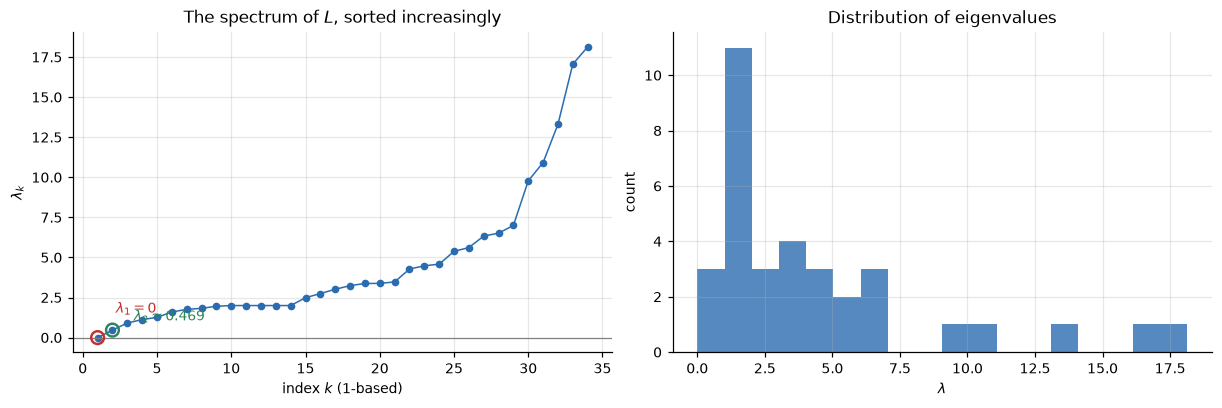

lambda_1  = 2.49e-16   (zero up to floating-point error)
lambda_2  = 0.468525
lambda_34 = 18.136696   (max degree is 17; note lambda_max >= d_max + 1)
trace(L)  = 156.0  ==  sum of eigenvalues = 156.0  ==  2|E| = 156


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

axes[0].plot(np.arange(1, n + 1), lam, "o-", ms=4, lw=1, color="#2b6cb0")
axes[0].axhline(0, color="gray", lw=0.8)
axes[0].scatter([1], [lam[0]], s=70, facecolor="none", edgecolor="#c53030", lw=1.6, zorder=5)
axes[0].scatter([2], [lam[1]], s=70, facecolor="none", edgecolor="#2f855a", lw=1.6, zorder=5)
axes[0].annotate(r"$\lambda_1 = 0$", (1, lam[0]), textcoords="offset points",
                 xytext=(12, 16), color="#c53030")
axes[0].annotate(r"$\lambda_2 \approx %.3f$" % lam[1], (2, lam[1]),
                 textcoords="offset points", xytext=(14, 6), color="#2f855a")
axes[0].set_xlabel("index $k$ (1-based)")
axes[0].set_ylabel(r"$\lambda_k$")
axes[0].set_title("The spectrum of $L$, sorted increasingly")

axes[1].hist(lam, bins=18, color="#2b6cb0", alpha=0.8)
axes[1].set_xlabel(r"$\lambda$")
axes[1].set_ylabel("count")
axes[1].set_title("Distribution of eigenvalues")
plt.show()

print(f"lambda_1  = {lam[0]:.2e}   (zero up to floating-point error)")
print(f"lambda_2  = {lam[1]:.6f}")
print(f"lambda_34 = {lam[-1]:.6f}   (max degree is {int(d.max())}; note lambda_max >= d_max + 1)")
print(f"trace(L)  = {np.trace(L):.1f}  ==  sum of eigenvalues = {lam.sum():.1f}  ==  2|E| = {2 * G.number_of_edges()}")

Two things are already readable off the spectrum. $\lambda_1 = 0$ exactly (up to rounding), and
the next eigenvalue $\lambda_2 \approx 0.469$ is clearly positive — Section 4 shows that this
gap is what certifies the graph is connected, and takes some care over whether $0.469$ should
count as small. And the
eigenvalues sum to $\operatorname{trace}(L) = \sum_i d_i = 2|E|$, since each edge contributes to
two degrees.

### What the eigenvectors mean: the quadratic form

Eigenvectors of $L$ look abstract until you see the quantity they optimise. For **any** vector
$q = (q_1,\dots,q_n)^\top \in \mathbb{R}^n$, a short calculation gives the key identity:

$$q^\top L q \;=\; \sum_{\{i,j\}\in E} (q_i - q_j)^2 .$$

The sum runs over **edges**, once per edge. Read it carefully: $q^\top L q$ is a measure of how
much $q$ **disagrees across edges**. It is zero exactly when $q$ takes the same value at both
ends of every edge, and it grows as neighbouring nodes take more different values. This quantity
has a name — the **Dirichlet energy**, or *smoothness*, of $q$ on the graph.

> ⚠️ **What $q$ is, and is not.** $q$ here is a **mathematical test pattern** — an arbitrary
> vector we are free to choose in order to probe the graph. It is *not* measured data. Assigning
> a number to each node is a mathematical operation, available to us because the graph has $n$
> nodes; it does not mean we went out and measured something. This distinction is the subject of
> the box after the next figure.

### Three things to know before using it

**(a) Two ways to write the same sum.** The identity above runs over **edges**, once per edge. The
form you will more often meet in the literature runs over **ordered pairs** of nodes and carries a
compensating $\tfrac12$:

$$q^\top L q \;=\; \sum_{\{i,j\}\in E} (q_i - q_j)^2 \;=\; \tfrac12 \sum_{i=1}^{n}\sum_{j=1}^{n} A_{ij}\,(q_i - q_j)^2 .$$

Each unordered edge $\{i,j\}$ appears twice in the double sum, once as $(i,j)$ and once as
$(j,i)$, and the $\tfrac12$ removes the duplication. Neither form is more correct; they differ only
in indexing. This notebook uses the edge form throughout. Check which one a paper means before
comparing numbers with it.

**(b) It carries squared units.** If $q$ is measured in volts then $q^\top L q$ is in volts$^2$.
Our $q$ is dimensionless here because no measurement has entered, but from the next lesson onwards
the units are real and must be stated.

**(c) It scales with the size of $q$, so raw values are not comparable.** Replacing $q$ by $cq$
multiplies the energy by $c^2$:

$$(cq)^\top L (cq) \;=\; c^2\, q^\top L q .$$

A "large" Dirichlet energy may therefore mean nothing more than a large $q$. To compare the
roughness of two different patterns, divide out the length — the **Rayleigh quotient**

$$\mathcal{R}(q) \;=\; \frac{q^\top L q}{q^\top q}$$

is the genuinely comparable quantity. This is also why we insist on **unit** eigenvectors below:
when $\|u_k\| = 1$ the two measures coincide.

### Where the name comes from

Give every edge an arbitrary orientation and build the **oriented incidence matrix**
$\nabla \in \mathbb{R}^{|E| \times n}$, one row per edge, carrying $-1$ at its tail and $+1$ at
its head. Then $(\nabla q)_e$ is the difference of $q$ across edge $e$ — a **discrete gradient** —
and

$$L = \nabla^\top \nabla, \qquad\text{so}\qquad q^\top L q = \|\nabla q\|^2 .$$

That is the discrete analogue of the continuous Dirichlet energy $\int |\nabla f|^2$, which is
where the name comes from. Two consequences are worth keeping. $L$ is a Gram matrix, which
re-proves positive semidefiniteness in one line (Section 4 does it again from the sum of squares).
And the arbitrary choice of orientation cancels, because the differences are squared — a fact that
stops being free in Lesson 5B, where signals live on edges and the orientation carries meaning.

Substituting a **unit** eigenvector ($\|u_k\|=1$) into the identity and using $Lu_k=\lambda_k u_k$:

$$u_k^\top L u_k \;=\; u_k^\top (\lambda_k u_k) \;=\; \lambda_k \, \|u_k\|^2 \;=\; \lambda_k .$$

**So each eigenvalue *is* the Dirichlet energy of its own eigenvector.** Small $\lambda_k$ means
$u_k$ varies gently across edges; large $\lambda_k$ means $u_k$ flips sharply between neighbours.
That is the precise sense in which $\lambda_k$ is a **graph frequency**, and why the ascending
ordering runs from smoothest to most oscillatory.

In [10]:
edge_idx = [(nodelist.index(u_), nodelist.index(v_)) for u_, v_ in G.edges()]

def dirichlet_energy(q):
    # Sum over edges of (q_i - q_j)^2, computed directly from the edge list.
    return sum((q[i] - q[j]) ** 2 for i, j in edge_idx)

def rayleigh(q):
    # Dirichlet energy per unit squared length -- the scale-free version.
    return (q @ L @ q) / (q @ q)

# Oriented incidence matrix: one row per edge, -1 at its tail and +1 at its head.
# The orientation is an arbitrary choice; it cancels below because differences are squared.
Nabla = np.zeros((G.number_of_edges(), n))
for e, (i, j) in enumerate(edge_idx):
    Nabla[e, i], Nabla[e, j] = -1.0, +1.0

q_test = rng.standard_normal(n)

# (a) One number, four ways -- and the identity holds for an ARBITRARY test pattern,
#     not only for eigenvectors.
ordered_pairs = 0.5 * sum(A[i, j] * (q_test[i] - q_test[j]) ** 2
                          for i in range(n) for j in range(n))
print("The same number, four ways (arbitrary test pattern q):")
print(f"  matrix form     q^T L q                        = {q_test @ L @ q_test:12.6f}")
print(f"  edge sum        sum_E (q_i - q_j)^2            = {dirichlet_energy(q_test):12.6f}")
print(f"  ordered pairs   (1/2) sum_ij A_ij (q_i-q_j)^2  = {ordered_pairs:12.6f}")
print(f"  gradient form   || grad q ||^2                 = "
      f"{np.linalg.norm(Nabla @ q_test) ** 2:12.6f}")
print(f"  and L == Nabla^T Nabla: {np.allclose(L, Nabla.T @ Nabla)}")
print()

# (b) Raw energy scales with ||q||^2; the Rayleigh quotient does not.
print("Rescaling q changes the energy but not the Rayleigh quotient:")
for c in [1, 2, 10]:
    print(f"  q scaled by {c:2d}:  q^T L q = {dirichlet_energy(c * q_test):11.3f}"
          f"    R(q) = {rayleigh(c * q_test):.6f}")
print()

# (c) For UNIT eigenvectors the quadratic form returns the eigenvalue itself, so
#     lambda_k is simultaneously the Dirichlet energy and the Rayleigh quotient of u_k.
print("  k   ||u_k||   u_k^T L u_k    lambda_k     edge sum      R(u_k)")
for k in [0, 1, 2, 16, 32, 33]:
    u_k = U[:, k]
    print(f" {k:2d}    {np.linalg.norm(u_k):.4f}   {u_k @ L @ u_k:11.6f}  {lam[k]:11.6f}  "
          f"{dirichlet_energy(u_k):11.6f}  {rayleigh(u_k):10.6f}")

The same number, four ways (arbitrary test pattern q):
  matrix form     q^T L q                        =   122.640249
  edge sum        sum_E (q_i - q_j)^2            =   122.640249
  ordered pairs   (1/2) sum_ij A_ij (q_i-q_j)^2  =   122.640249
  gradient form   || grad q ||^2                 =   122.640249
  and L == Nabla^T Nabla: True

Rescaling q changes the energy but not the Rayleigh quotient:
  q scaled by  1:  q^T L q =     122.640    R(q) = 5.141583
  q scaled by  2:  q^T L q =     490.561    R(q) = 5.141583
  q scaled by 10:  q^T L q =   12264.025    R(q) = 5.141583

  k   ||u_k||   u_k^T L u_k    lambda_k     edge sum      R(u_k)
  0    1.0000     -0.000000     0.000000     0.000000   -0.000000
  1    1.0000      0.468525     0.468525     0.468525    0.468525
  2    1.0000      0.909248     0.909248     0.909248    0.909248
 16    1.0000      3.013963     3.013963     3.013963    3.013963
 32    1.0000     17.055171    17.055171    17.055171   17.055171
 33    1.0000     1

Now we can *see* the eigenvectors. Each one assigns a number to every node, so we colour the
nodes by that number: red for positive, blue for negative, pale for near zero. The colour scale
is centred at zero and rescaled per panel, because only the *pattern* of signs and relative
magnitudes is meaningful.

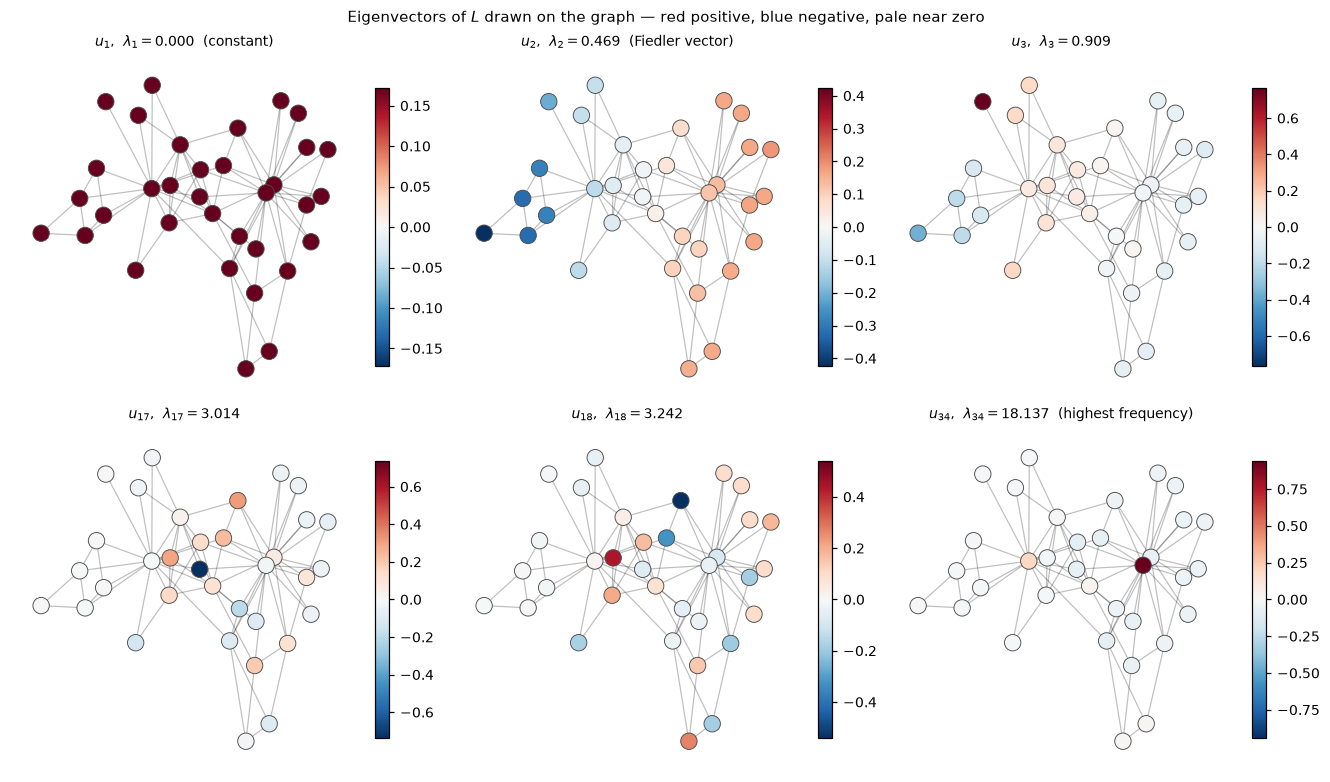

In [11]:
def draw_vector_on_graph(ax, vec, title):
    # Colour nodes by the entries of vec, diverging around zero.
    lim = np.abs(vec).max()
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.25, width=0.8)
    nodes = nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=nodelist, node_color=vec,
                                   cmap="RdBu_r", vmin=-lim, vmax=lim, node_size=115,
                                   edgecolors="0.3", linewidths=0.6)
    ax.set_title(title, fontsize=9)
    ax.set_axis_off()
    ax.grid(False)
    return nodes

show_k = [0, 1, 2, 16, 17, 33]      # low order, middle order, highest order
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, k in zip(axes.ravel(), show_k):
    label = {0: "  (constant)", 1: "  (Fiedler vector)", 33: "  (highest frequency)"}.get(k, "")
    nodes = draw_vector_on_graph(ax, U[:, k],
                                 f"$u_{{{k + 1}}}$,  $\\lambda_{{{k + 1}}} = {lam[k]:.3f}${label}")
    fig.colorbar(nodes, ax=ax, fraction=0.04)
fig.suptitle("Eigenvectors of $L$ drawn on the graph — red positive, blue negative, pale near zero",
             fontsize=10)
plt.show()

Read the panels left to right, top to bottom, in order of increasing $\lambda$:

- **$u_1$ ($\lambda_1 = 0$)** is constant — every node identical. Its Dirichlet energy is zero
  because it disagrees across no edge at all. It carries no information about this graph beyond
  "it is connected" (Section 4).
- **$u_2$ ($\lambda_2 \approx 0.469$)** is the smoothest *non-constant* pattern available. It is
  strongly negative on one side of the graph and strongly positive on the other, changing sign
  once, in the sparse middle. This is the Fiedler vector and the subject of Section 4.
- **$u_3$** does something different: rather than dividing the graph into two halves, it
  concentrates most of its magnitude on a few peripheral nodes — note the one strongly
  coloured node with almost everything else pale. Section 5 shows why that distinction
  matters in practice.
- **Middle-order $u_{17}, u_{18}$** are scattered: patches of red and blue interleave, with no
  large coherent region.
- **$u_{34}$ ($\lambda_{34} \approx 18.1$)** is the roughest pattern the graph supports — it
  concentrates on a hub and its immediate neighbours with alternating signs, disagreeing across
  nearly every edge it touches.

We can turn "oscillatory" into a number by counting how many edges have endpoints of opposite
sign — a discrete analogue of counting the zero crossings of a sinusoid.

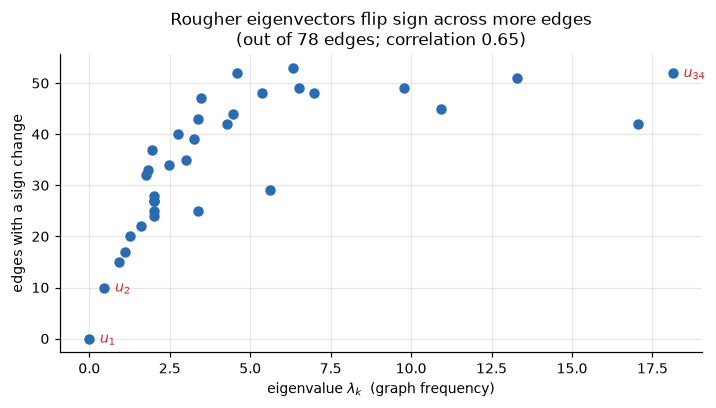

u_1  :  0 sign-change edges  (constant -- none, by construction)
u_2  : 10 sign-change edges  (one clean cut)
u_34 : 52 sign-change edges  (out of 78)


In [12]:
# Count edges whose two endpoints carry opposite signs, for each eigenvector.
sign_changes = np.array([sum(1 for i, j in edge_idx if U[i, k] * U[j, k] < 0)
                         for k in range(n)])

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.scatter(lam, sign_changes, s=34, color="#2b6cb0", zorder=3)
for k in [0, 1, 33]:
    ax.annotate(f"$u_{{{k + 1}}}$", (lam[k], sign_changes[k]),
                textcoords="offset points", xytext=(7, -3), fontsize=9, color="#c53030")
ax.set_xlabel(r"eigenvalue $\lambda_k$  (graph frequency)")
ax.set_ylabel("edges with a sign change")
ax.set_title(f"Rougher eigenvectors flip sign across more edges\n"
             f"(out of {G.number_of_edges()} edges; correlation "
             f"{np.corrcoef(lam, sign_changes)[0, 1]:.2f})")
plt.show()

print(f"u_1  : {sign_changes[0]:2d} sign-change edges  (constant -- none, by construction)")
print(f"u_2  : {sign_changes[1]:2d} sign-change edges  (one clean cut)")
print(f"u_34 : {sign_changes[-1]:2d} sign-change edges  (out of {G.number_of_edges()})")

The trend is clearly upward but **not monotone** — $u_{20}$, for instance, sits well below the
line. On a path or a cycle, eigenvector $k$ has exactly $k-1$ sign changes and the relationship
is exact; on an irregular graph like this one, "graph frequency" is a genuine but approximate
ordering. Saying it is exactly like Fourier frequency would be overclaiming. The reliable
statement is the quadratic form: $\lambda_k = u_k^\top L u_k$ is *precisely* the Dirichlet energy
of $u_k$, always.

> ### 🔑 Spectrum vs. graph Fourier transform — the distinction, stated precisely
>
> We have now computed a full eigenbasis $U$ without ever using data. That is the point.
>
> **The spectrum is a property of the graph.** $\{\lambda_k\}$ and $\{u_k\}$ were derived from
> $L$, which was derived from $E$. Nothing was measured. Every picture in this lesson shows the
> graph describing *itself*.
>
> **The graph Fourier transform needs a signal.** Suppose you additionally measure something at
> each node — a temperature, an opinion, a sensor reading — giving a vector
> $x \in \mathbb{R}^n$ where $x_i$ is the value at node $i$. Because $U$ is an orthonormal basis,
> you can expand $x$ in it:
> $$\hat{x} = U^\top x, \qquad \hat{x}_k = u_k^\top x, \qquad x = U\hat{x} = \sum_{k=1}^n \hat{x}_k u_k .$$
> The vector $\hat{x}$ is the **graph Fourier transform** of $x$: the amount of each
> graph-frequency pattern present in *your data*. A signal with $\hat{x}$ concentrated at small
> $k$ is smooth over the network; energy at large $k$ means neighbouring nodes disagree.
>
> **Why they get confused.** Both produce a number per node that you colour a graph with. But
> $u_k$ is a pattern the graph *defines*, while $x$ is a pattern the world *hands you*. The
> karate club has no measured signal, so this lesson stops at the basis. The distinction matters
> the moment you have real data: changing $E$ changes the basis, whereas changing $x$ changes
> only the coefficients.

> 📖 **Reference — graph frequency.**
> [Shuman, Narang, Frossard, Ortega & Vandergheynst, *The Emerging Field of Signal Processing on
> Graphs* (2013)](https://arxiv.org/abs/1211.0053). Sections II–III make the frequency analogy
> above precise and define the GFT properly. Read it for the bridge from this lesson to the next:
> it is where the spectrum stops being a description of the graph and becomes a tool for
> analysing signals on it.

---
## 4. Connectivity and bottlenecks

Three facts follow from the quadratic form, and together they turn the spectrum into a
structural diagnosis.

**(i) Every eigenvalue is non-negative.** For any $q$, $q^\top L q = \sum_{\{i,j\}\in E}(q_i-q_j)^2 \ge 0$
as a sum of squares, so $L$ is positive semidefinite. With $q = u_k$ this gives
$\lambda_k \ge 0$ for all $k$. The spectrum lives in $[0,\infty)$.

**(ii) The multiplicity of the eigenvalue $0$ equals the number of connected components.**
Suppose $Lq = 0$. Then $q^\top L q = 0$, so $\sum_{\{i,j\}\in E}(q_i-q_j)^2 = 0$, which forces
$q_i = q_j$ across **every** edge. So $q$ must be constant on each connected component, and free
to take a different value on each. If the graph has $c$ components, the space of such $q$ has
dimension exactly $c$ — a basis is the set of indicator vectors of the components. Hence

$$\dim\ker(L) \;=\; \#\{k : \lambda_k = 0\} \;=\; c .$$

Counting zero eigenvalues counts the pieces of the graph. Our graph has $\lambda_1=0<\lambda_2$,
so $c=1$: connected, as NetworkX reported.

**(iii) $\lambda_2$ measures *how well* connected the graph is.** Since $\lambda_2 > 0$ exactly
when the graph is connected, and small $\lambda_2$ means there is a nearly-disconnecting pattern,
$\lambda_2$ is called the **algebraic connectivity** (Fiedler, 1973). Its eigenvector $u_2$ is
the **Fiedler vector**.

In [13]:
# Demonstrate (ii) on a graph built to have exactly three components.
H = nx.disjoint_union_all([nx.cycle_graph(4), nx.path_graph(3), nx.empty_graph(1)])
H_nodes = sorted(H.nodes())
A_H = nx.to_numpy_array(H, nodelist=H_nodes, weight=None)
L_H = np.diag(A_H.sum(axis=1)) - A_H
lam_H = np.linalg.eigvalsh(L_H)

print("Test graph: a 4-cycle, a 3-path, and one isolated node")
print("  spectrum        :", np.round(lam_H, 6))
print("  zero eigenvalues:", int(np.sum(np.abs(lam_H) < 1e-10)))
print("  nx components   :", nx.number_connected_components(H))
print()
print("Karate club:")
print(f"  lambda_1 = {lam[0]:.2e}, lambda_2 = {lam[1]:.6f}  -> exactly one zero -> connected")
print(f"  zero eigenvalues: {int(np.sum(np.abs(lam) < 1e-10))}, "
      f"nx components: {nx.number_connected_components(G)}")

Test graph: a 4-cycle, a 3-path, and one isolated node
  spectrum        : [-0.  0.  0.  1.  2.  2.  3.  4.]
  zero eigenvalues: 3
  nx components   : 3

Karate club:
  lambda_1 = 2.49e-16, lambda_2 = 0.468525  -> exactly one zero -> connected
  zero eigenvalues: 1, nx components: 1


### Is $0.469$ small?

We have called $\lambda_2$ the algebraic connectivity and said it measures how hard the graph is to
disconnect. But $0.469$ on its own is not yet a finding: small compared to *what*? An eigenvalue
reported without a scale invites the reader to supply their own, and the obvious guess — "close to
zero, so the club was barely holding together" — turns out to be wrong.

Three yardsticks are available, in increasing order of effort.

**1. An analytic bound.** For any graph on $n$ nodes,

$$\lambda_2 \;\le\; \frac{n}{n-1}\, d_{\min},$$

where $d_{\min}$ is the smallest degree. Our graph contains a member with exactly one contact, so
$d_{\min}=1$ and $\lambda_2$ **cannot exceed** $34/33 \approx 1.03$ however the edges are
arranged. Any reading of $0.469$ has to be made against that ceiling, not against infinity.

**2. Reference graphs.** Evaluate $\lambda_2$ on graphs whose structure we already understand — a
path, about as strung out as a connected graph gets, and a complete graph, maximally connected — at
the same number of nodes.

**3. A null model.** Ask what $\lambda_2$ would be for a graph sharing the club's degree sequence
but otherwise random. Repeatedly applying a **double edge swap** — take two edges $\{a,b\}$ and
$\{c,d\}$ and replace them with $\{a,d\}$ and $\{c,b\}$ — rewires the graph while leaving every
degree untouched. The resulting ensemble answers a sharper question than "is $0.469$ near zero?":
*is this network easier to split than its degree sequence alone would predict?*

In [14]:
# --- yardstick 1: the analytic ceiling -----------------------------------------
d_min = int(d.min())
ceiling = n / (n - 1) * d_min
print(f"observed lambda_2                 = {lam[1]:.4f}")
print(f"ceiling  n/(n-1) * d_min          = {ceiling:.4f}   (d_min = {d_min}; node "
      f"{nodelist[int(np.argmin(d))]} has a single contact)")
print(f"observed as a fraction of ceiling = {lam[1] / ceiling:.1%}")
print()

# --- yardstick 2: graphs whose structure we already understand ------------------
def lambda_2(g):
    A_ = nx.to_numpy_array(g, nodelist=sorted(g.nodes()), weight=None)
    return np.linalg.eigvalsh(np.diag(A_.sum(axis=1)) - A_)[1]

print(f"path graph P_{n}   (barely connected)  lambda_2 = {lambda_2(nx.path_graph(n)):.4f}")
print(f"karate club                            lambda_2 = {lam[1]:.4f}")
print(f"complete graph K_{n} (maximally so)    lambda_2 = {lambda_2(nx.complete_graph(n)):.4f}")
print()

# --- yardstick 3: degree-preserving rewiring null -------------------------------
# double_edge_swap rearranges edges while holding every node's degree fixed, so the
# ensemble differs from the club ONLY in how those edges are arranged.
def fiedler_cut_size(g):
    # Edges crossing the sign partition of that graph's OWN Fiedler vector.
    nl_ = sorted(g.nodes())
    where = {v: i for i, v in enumerate(nl_)}
    A_ = nx.to_numpy_array(g, nodelist=nl_, weight=None)
    _, U_ = np.linalg.eigh(np.diag(A_.sum(axis=1)) - A_)
    side = U_[:, 1] > 0
    return sum(1 for a, b in g.edges() if side[where[a]] != side[where[b]])

N_NULL = 500
null_lam2, null_cut, n_dropped, null_example = [], [], 0, None
for s in range(N_NULL):
    H_null = G.copy()
    nx.double_edge_swap(H_null, nswap=10 * G.number_of_edges(), max_tries=100_000, seed=SEED + s)
    if not nx.is_connected(H_null):       # lambda_2 = 0 there; we compare within connected graphs
        n_dropped += 1
        continue
    null_lam2.append(lambda_2(H_null))
    null_cut.append(fiedler_cut_size(H_null))
    null_example = H_null                 # kept for the degree-preservation check in Section 6
null_lam2, null_cut = np.array(null_lam2), np.array(null_cut)

print(f"{len(null_lam2)} degree-preserving rewirings ({n_dropped} discarded as disconnected)")
print(f"  degree sequence unchanged: "
      f"{sorted(dd for _, dd in null_example.degree()) == sorted(dd for _, dd in G.degree())}")
print(f"  rewired lambda_2 : mean {null_lam2.mean():.4f}   median {np.median(null_lam2):.4f}   "
      f"5th pct {np.percentile(null_lam2, 5):.4f}")
print(f"  observed lambda_2: {lam[1]:.4f}")
print(f"  rewirings at least as splittable (lambda_2 <= observed): "
      f"{np.mean(null_lam2 <= lam[1]):.1%}")

observed lambda_2                 = 0.4685
ceiling  n/(n-1) * d_min          = 1.0303   (d_min = 1; node 11 has a single contact)
observed as a fraction of ceiling = 45.5%

path graph P_34   (barely connected)  lambda_2 = 0.0085
karate club                            lambda_2 = 0.4685
complete graph K_34 (maximally so)    lambda_2 = 34.0000



500 degree-preserving rewirings (0 discarded as disconnected)
  degree sequence unchanged: True
  rewired lambda_2 : mean 0.7117   median 0.7342   5th pct 0.3726
  observed lambda_2: 0.4685
  rewirings at least as splittable (lambda_2 <= observed): 9.8%


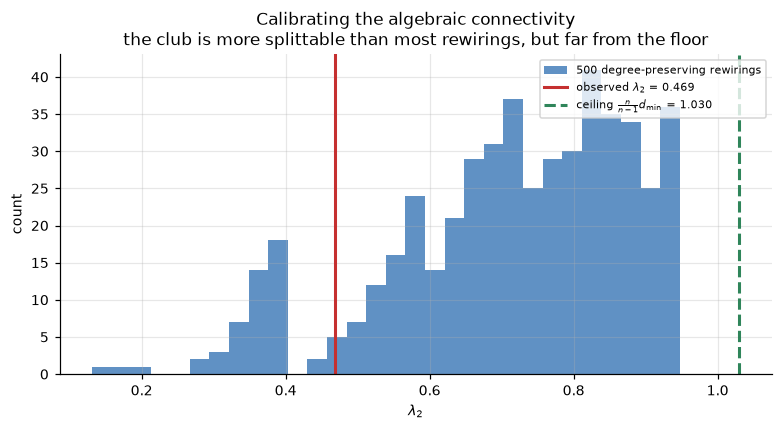

In [15]:
fig, ax = plt.subplots(figsize=(7.0, 3.8))
ax.hist(null_lam2, bins=30, color="#2b6cb0", alpha=0.75,
        label=f"{len(null_lam2)} degree-preserving rewirings")
ax.axvline(lam[1], color="#c53030", lw=2.0,
           label=f"observed $\\lambda_2$ = {lam[1]:.3f}")
ax.axvline(ceiling, color="#2f855a", lw=2.0, ls="--",
           label=f"ceiling $\\frac{{n}}{{n-1}}d_{{\\min}}$ = {ceiling:.3f}")
ax.set_xlabel(r"$\lambda_2$")
ax.set_ylabel("count")
ax.set_title("Calibrating the algebraic connectivity\n"
             "the club is more splittable than most rewirings, but far from the floor")
ax.legend(fontsize=7.5, loc="upper right")
plt.show()

Three readings, and they do not all say the same thing.

The **ceiling** is the strongest constraint and the easiest to miss. Because one member has a
single contact, $\lambda_2$ could not have exceeded $1.03$ for *any* rearrangement of these edges.
At $0.469$ the club sits at roughly **45% of its own maximum**, not near zero. The intuitive
reading — "$0.469$ is close to $0$, so the network was barely holding together" — is an artefact of
comparing against a scale this graph could never reach.

The **reference graphs** confirm it. A 34-node path, about as stringy as a connected graph gets,
has $\lambda_2 \approx 0.0085$: fifty-five times smaller. The club is nowhere near that regime.

The **null model** supplies the genuine finding. Only about 10% of degree-preserving rewirings
are at least as easy to split, so the club really is more separable than its degree sequence alone
would predict. That is a modest but real effect — roughly one in ten, not overwhelming — and it
is a statement about *edge arrangement*, which is exactly what this section set out to study.

> ⚠️ **What this null model does and does not randomise.** Each rewiring keeps every node's degree
> and changes only which pairs are joined, so the comparison isolates edge *arrangement*. It says
> nothing about whether the degree sequence itself is unusual, and nothing about signals — there are
> none in this lesson. The next lesson uses the mirror image: hold the graph fixed and permute a
> measured signal across the nodes, testing whether *data* aligns with the structure. Same tool,
> opposite side of the spectrum-versus-signal distinction.

Three components, three zero eigenvalues. The isolated node contributes a zero row and column to
$L$, hence its own zero eigenvalue.

### Why $u_2$ finds the bottleneck

Ask directly for the pattern that disagrees across edges as *little as possible*. The constant
vector wins trivially with energy $0$, so we must exclude it. Two constraints do this:

$$\lambda_2 \;=\; \min_{\|q\| = 1,\; q^\top \mathbf{1} = 0} \; q^\top L q
\;=\; \min_{\|q\| = 1,\; q^\top \mathbf{1} = 0} \sum_{\{i,j\}\in E} (q_i - q_j)^2,$$

and the minimiser is $q = u_2$. The constraints read:

- $\|q\| = 1$ — fix the scale, otherwise shrinking $q$ shrinks the energy for free;
- $q^\top \mathbf{1} = \sum_i q_i = 0$ — be orthogonal to the constant vector, i.e. genuinely
  vary rather than being uniform. This forces $q$ to take both positive and negative values.

(This is the Courant–Fischer characterisation, applied at $k=2$.)

So $u_2$ is the answer to: *assign numbers to nodes, summing to zero, so that connected nodes get
numbers as similar as possible.* The only way to satisfy both is to give one region negative
values and another positive values, and place the transition **where there are fewest edges to
pay for** — exactly a bottleneck. The value of the minimum, $\lambda_2$, is how much that
cheapest cut costs.

Splitting nodes by the **sign** of $u_2$ is therefore a principled two-way partition.

In [16]:
fiedler = U[:, 1]                      # u_2, the Fiedler vector (NumPy index 1)

print(f"||u_2||          = {np.linalg.norm(fiedler):.6f}   (unit norm)")
print(f"sum of entries   = {fiedler.sum(): .2e}   (orthogonal to the constant vector)")
print(f"u_2^T L u_2      = {fiedler @ L @ fiedler:.6f}  ==  lambda_2 = {lam[1]:.6f}")
print()

# Check the variational claim numerically: random admissible q never beats lambda_2.
best = np.inf
for _ in range(20000):
    q = rng.standard_normal(n)
    q -= q.mean()                      # enforce q^T 1 = 0
    q /= np.linalg.norm(q)             # enforce ||q|| = 1
    best = min(best, q @ L @ q)
print(f"lambda_2                            = {lam[1]:.6f}")
print(f"best of 20000 random admissible q   = {best:.6f}   (never below lambda_2)")

||u_2||          = 1.000000   (unit norm)
sum of entries   =  9.15e-15   (orthogonal to the constant vector)
u_2^T L u_2      = 0.468525  ==  lambda_2 = 0.468525



lambda_2                            = 0.468525
best of 20000 random admissible q   = 2.109995   (never below lambda_2)


In [17]:
# Partition by the SIGN of the Fiedler vector. This uses only the edges -- no labels.
partition = fiedler > 0
side_A = [nodelist[i] for i in range(n) if not partition[i]]
side_B = [nodelist[i] for i in range(n) if partition[i]]

print(f"Group '-' ({len(side_A):2d} nodes): {side_A}")
print(f"Group '+' ({len(side_B):2d} nodes): {side_B}")
print()
cut_edges = [(nodelist[i], nodelist[j]) for i, j in edge_idx if partition[i] != partition[j]]
print(f"Edges cut by this partition: {len(cut_edges)} of {G.number_of_edges()} "
      f"({100 * len(cut_edges) / G.number_of_edges():.0f}%)")
print(f"Cut edges: {cut_edges}")

Group '-' (15 nodes): [0, 1, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Group '+' (19 nodes): [2, 8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]

Edges cut by this partition: 10 of 78 (13%)
Cut edges: [(0, 2), (0, 8), (0, 31), (1, 2), (1, 30), (2, 3), (2, 7), (2, 13), (13, 33), (19, 33)]


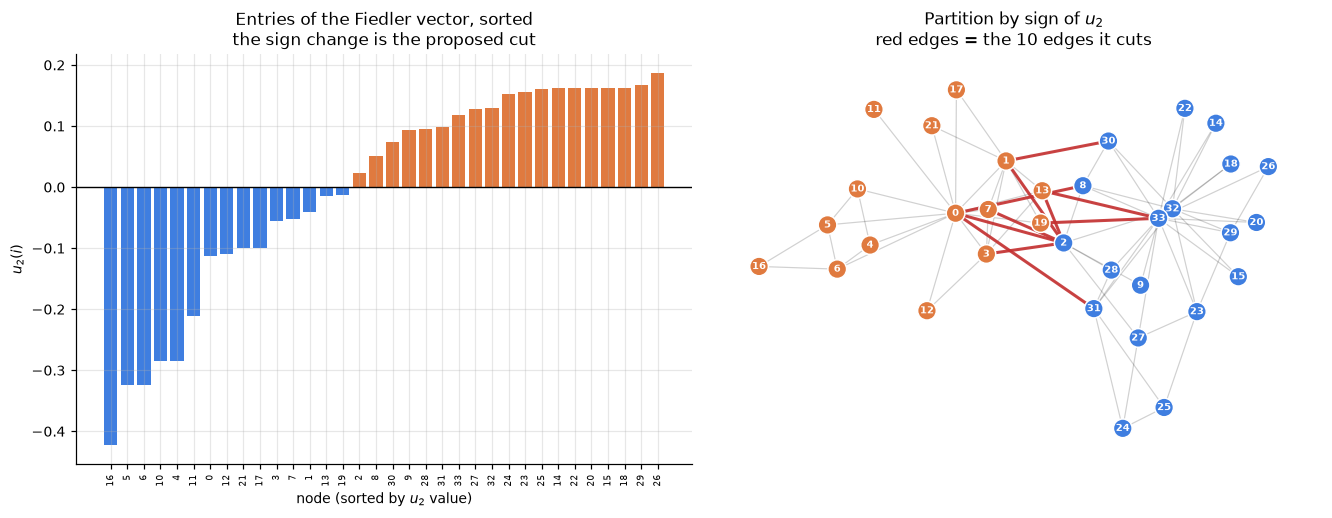

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

# Left: the Fiedler vector's entries, sorted, showing the gap it opens at zero.
srt = np.argsort(fiedler)
bar_colours = ["#3f7ee0" if fiedler[i] <= 0 else "#e07a3f" for i in srt]
axes[0].bar(range(n), fiedler[srt], color=bar_colours)
axes[0].axhline(0, color="black", lw=0.9)
axes[0].set_xticks(range(n))
axes[0].set_xticklabels([nodelist[i] for i in srt], fontsize=6, rotation=90)
axes[0].set_xlabel("node (sorted by $u_2$ value)")
axes[0].set_ylabel(r"$u_2(i)$")
axes[0].set_title("Entries of the Fiedler vector, sorted\nthe sign change is the proposed cut")

# Right: the partition drawn on the graph, cut edges highlighted.
nx.draw_networkx_edges(G, pos, ax=axes[1], alpha=0.18, width=0.8)
nx.draw_networkx_edges(G, pos, ax=axes[1], edgelist=cut_edges, edge_color="#c53030",
                       width=2.0, alpha=0.9)
nx.draw_networkx_nodes(G, pos, ax=axes[1], nodelist=nodelist,
                       node_color=["#3f7ee0" if p else "#e07a3f" for p in partition],
                       node_size=150, edgecolors="white", linewidths=1.0)
nx.draw_networkx_labels(G, pos, ax=axes[1], font_size=6.5, font_color="white", font_weight="bold")
axes[1].set_title(f"Partition by sign of $u_2$\nred edges = the {len(cut_edges)} edges it cuts")
axes[1].set_axis_off()
axes[1].grid(False)
plt.show()

The sorted plot shows the structure: a block of clearly negative values, a block of clearly
positive values, and a handful of nodes hovering near zero. Those near-zero nodes are the
ambiguous ones — the members with contacts on both sides — and they are where any sign-based cut
is fragile.

### Scoring against history

Only **now** do we look at the recorded split, purely to evaluate.

In [19]:
# Ground truth, used here for the FIRST time and only for scoring.
truth = np.array([club[v] == "Mr. Hi" for v in nodelist])

# The sign of an eigenvector is arbitrary (Section 5), so a partition and its complement are
# the same partition. Score both alignments and keep the better one.
agree = (partition == truth)
if agree.mean() < 0.5:
    agree = ~agree
accuracy = agree.mean()

print(f"Nodes agreeing with the historical split: {agree.sum()} / {n}  ({accuracy:.1%})")
print()
mismatched = [nodelist[i] for i in np.flatnonzero(~agree)]
print(f"Disagreements: nodes {mismatched}")
for v in mismatched:
    i = nodelist.index(v)
    nbrs = list(G.neighbors(v))
    same = sum(1 for w in nbrs if club[w] == club[v])
    print(f"   node {v:2d}: u_2 = {fiedler[i]:+.4f} (|u_2| rank {np.argsort(np.abs(fiedler)).tolist().index(i) + 1} "
          f"of {n}, i.e. near zero), degree {len(nbrs)}, "
          f"{same} of {len(nbrs)} neighbours in its own faction '{club[v]}'")

Nodes agreeing with the historical split: 32 / 34  (94.1%)

Disagreements: nodes [2, 8]
   node  2: u_2 = +0.0232 (|u_2| rank 3 of 34, i.e. near zero), degree 10, 6 of 10 neighbours in its own faction 'Mr. Hi'
   node  8: u_2 = +0.0516 (|u_2| rank 5 of 34, i.e. near zero), degree 5, 2 of 5 neighbours in its own faction 'Mr. Hi'


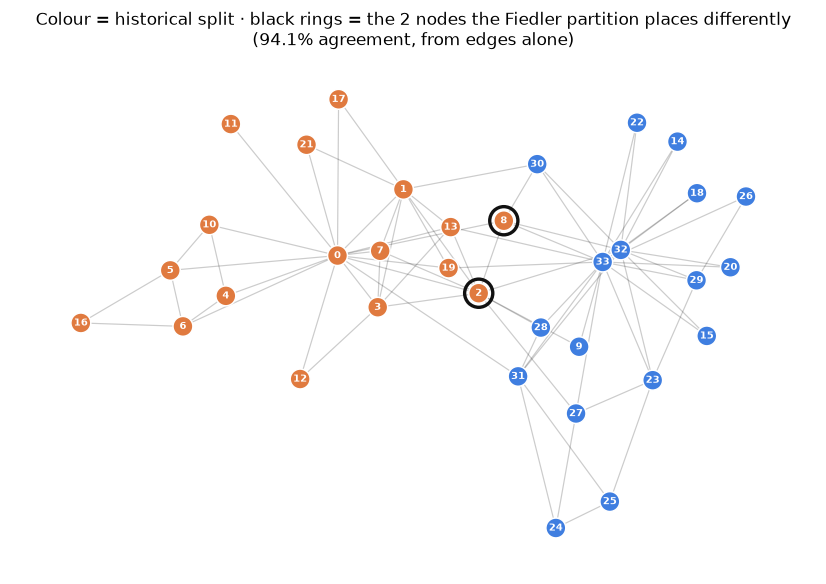

In [20]:
fig, ax = plt.subplots(figsize=(7.4, 5.2))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.2, width=0.8)
nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=nodelist,
                       node_color=["#e07a3f" if club[v] == "Mr. Hi" else "#3f7ee0" for v in nodelist],
                       node_size=170, edgecolors="white", linewidths=1.0)
wrong = [nodelist[i] for i in np.flatnonzero(~agree)]
nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=wrong, node_color="none",
                       node_size=340, edgecolors="#111111", linewidths=2.2)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=6.5, font_color="white", font_weight="bold")
ax.set_title(f"Colour = historical split · black rings = the {len(wrong)} nodes the Fiedler "
             f"partition places differently\n({accuracy:.1%} agreement, from edges alone)")
ax.set_axis_off()
ax.grid(False)
plt.show()

**Around 94% agreement, computed without ever looking at the labels.** The structure of who
talked to whom in 1970 substantially anticipated who went where when the club broke up.

### Is 94% good?

The question we just asked of $\lambda_2$ applies to the score as well. $94.1\%$ sounds
convincing, but a percentage means nothing on its own. Two comparisons are worth making, and they
check different things.

**Is the cut itself unusual?** We already have 500 degree-preserving rewirings from earlier in this
section, each with its own Fiedler cut. If the club's 10-edge cut is typical of that ensemble, then
the *size* of the cut is not the remarkable part.

**Would a simpler method have done as well?** Spectral partitioning is not the only way to split a
network. Two standard community-detection algorithms need no eigenvectors at all, and we add a
deliberately crude rule — assign each member to whichever leader they can reach in fewer steps — as
a floor.


In [21]:
from networkx.algorithms.community import girvan_newman, greedy_modularity_communities

# --- comparison 1: is the CUT SIZE unusual, given the degree sequence? ---------
obs_cut = len(cut_edges)
print(f"Fiedler cut on the club                : {obs_cut} edges")
print(f"Fiedler cut on rewired graphs          : mean {null_cut.mean():.1f} edges, "
      f"median {np.median(null_cut):.0f}")
print(f"rewirings cutting {obs_cut} edges or fewer      : {np.mean(null_cut <= obs_cut):.1%}")
print()

# --- comparison 2: what do simpler, non-spectral methods score? ---------------
def agreement(membership):
    # Fraction matching the recorded split, maximised over the arbitrary label swap.
    a = np.asarray(membership, dtype=bool) == truth
    return max(a.mean(), 1 - a.mean())

# (a) Girvan-Newman: repeatedly remove the highest-betweenness edge; take the first split.
gn_first = next(girvan_newman(G))
gn_score = agreement([v in gn_first[0] for v in nodelist])

# (b) Greedy modularity maximisation, stopped at two communities.
gm = greedy_modularity_communities(G, weight=None, cutoff=2, best_n=2)
gm_score = agreement([v in gm[0] for v in nodelist])

# (c) A crude floor, no algorithm at all: whichever leader is fewer hops away.
hops_hi, hops_off = nx.shortest_path_length(G, 0), nx.shortest_path_length(G, 33)
hub_score = agreement([hops_hi[v] <= hops_off[v] for v in nodelist])

print(f"{'method':<32s}{'uses eigenvectors':>19s}{'agreement':>12s}")
print(f"{'sign of u_2 (this lesson)':<32s}{'yes':>19s}{accuracy:>12.1%}")
print(f"{'Girvan-Newman, first split':<32s}{'no':>19s}{gn_score:>12.1%}")
print(f"{'greedy modularity (k=2)':<32s}{'no':>19s}{gm_score:>12.1%}")
print(f"{'nearer leader in hops':<32s}{'no':>19s}{hub_score:>12.1%}")

Fiedler cut on the club                : 10 edges
Fiedler cut on rewired graphs          : mean 15.5 edges, median 17
rewirings cutting 10 edges or fewer      : 22.6%

method                            uses eigenvectors   agreement
sign of u_2 (this lesson)                       yes       94.1%
Girvan-Newman, first split                       no       94.1%
greedy modularity (k=2)                          no       94.1%
nearer leader in hops                            no       91.2%


**The spectral partition ties both standard alternatives and beats the crude rule by a single
member.** And the cut is unexceptional: roughly a quarter of the rewirings achieve a Fiedler cut of
10 edges or fewer, so 10 edges is an ordinary cut for a graph with this degree sequence.

State that plainly rather than burying it. On this dataset the spectrum is **not** more accurate
than established community detection, and $94.1\%$ is not evidence that it is. If recovering the
split were the only goal, Girvan–Newman would serve just as well and needs no linear algebra.

So what did the spectrum buy? Something the alternatives do not provide: a **continuous score per
node**. Girvan–Newman and modularity return set membership — node 2 is in group A, full stop. The
Fiedler vector returns $u_2(2) = +0.023$, and the two members it places differently rank 3rd and
5th smallest in $|u_2|$ out of 34. The method grades its own confidence, node by node, and that
ranking is what the next subsection interprets.

This is the general shape of an honest claim about a spectral method. It earns its place by what it
*represents* — an ordered basis, a graded embedding, a frequency axis — more often than by winning
an accuracy contest against a purpose-built algorithm.

### Why it should *not* match perfectly

A perfect score would actually be suspicious. The two answers are answers to different questions:

- **$u_2$ answers a graph question**: which cut separates the network while crossing the fewest
  edges, weighing every edge equally.
- **The split is a human outcome**: it depended on loyalty, convenience, who was asked first, and
  facts never recorded in this graph.

The disagreeing nodes are precisely the ones whose $u_2$ values sit nearest zero — the members
with substantial contact on both sides, for whom the graph itself expresses no strong preference.
The model is not confidently wrong about them; it is correctly reporting that they are ambiguous.
Reading the magnitude $|u_2(i)|$ as a confidence is part of interpreting the result properly.

Two further caveats on the method itself. Thresholding $u_2$ at zero is a **relaxation**: the
exact balanced-minimum-cut problem is NP-hard, and the Fiedler vector is the solution to a
continuous problem that we then round. Rounding at zero is also just one choice — the median, or
the largest gap in the sorted values, are equally defensible and can give a different answer.

> 📖 **Reference — the theory behind this section.**
> [von Luxburg, *A Tutorial on Spectral Clustering* (2007)](https://arxiv.org/abs/0711.0189).
> This is the main reference for everything here and in Section 5. Section 3 states and proves the
> zero-multiplicity result; Section 5 derives the sign-of-$u_2$ partition as the relaxation of a
> discrete minimum-cut problem, which is what tells you *why* the relaxation is reasonable and
> where it can fail.

---
## 5. Spectral embedding, and which matrix to use

### Coordinates from eigenvectors

The Fiedler vector gave each node one number. Nothing stops us from using several. Taking the
next two eigenvectors after the constant one, define the map

$$i \;\longmapsto\; \big(u_2(i),\, u_3(i)\big) \in \mathbb{R}^2,$$

where $u_k(i)$ denotes entry $i$ of eigenvector $u_k$. This is the **spectral embedding**: it
places every node at a point in the plane using only the graph's connectivity. We skip $u_1$
because it is constant and would give every node the same coordinate.

Unlike the spring layout of Section 1, **these coordinates are computed, not chosen**. Distance
in this plot does mean something: nodes that the graph considers structurally similar — well
connected to each other, hard to separate — land near each other, because both coordinates are
patterns that vary slowly across edges.

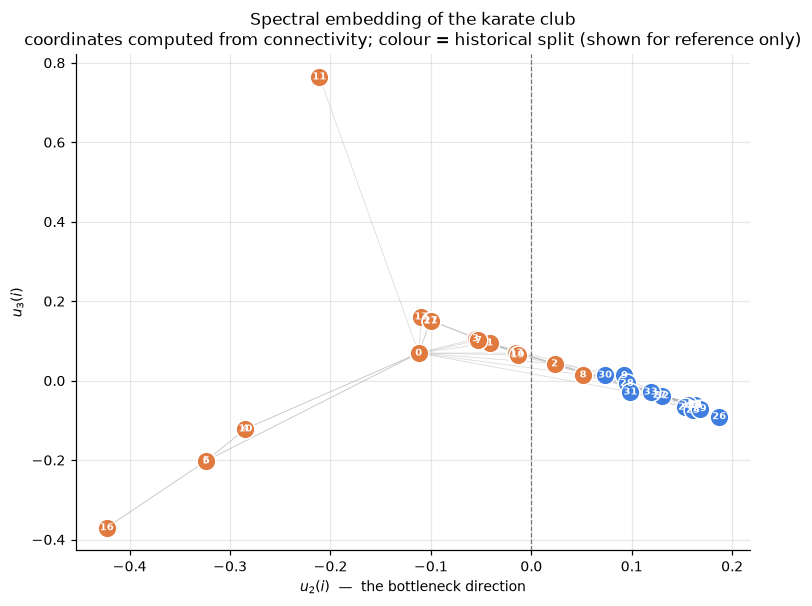

In [22]:
embedding = np.column_stack([U[:, 1], U[:, 2]])       # coordinates (u_2(i), u_3(i))

fig, ax = plt.subplots(figsize=(6.8, 5.4))
for i, v in enumerate(nodelist):
    ax.scatter(*embedding[i], s=150, zorder=3,
               color="#e07a3f" if club[v] == "Mr. Hi" else "#3f7ee0",
               edgecolor="white", linewidth=1.0)
    ax.annotate(str(v), embedding[i], fontsize=6.5, color="white",
                ha="center", va="center", zorder=4, fontweight="bold")
for i, j in edge_idx:
    ax.plot(*zip(embedding[i], embedding[j]), color="0.7", lw=0.5, alpha=0.5, zorder=1)
ax.axvline(0, color="black", lw=0.8, ls="--", alpha=0.5)
ax.set_xlabel(r"$u_2(i)$  —  the bottleneck direction")
ax.set_ylabel(r"$u_3(i)$")
ax.set_title("Spectral embedding of the karate club\ncoordinates computed from connectivity; "
             "colour = historical split (shown for reference only)")
plt.show()

The horizontal axis separates the two factions — that is the Fiedler vector at work, and the
dashed line is the sign threshold from Section 4. Nodes near the origin are the structurally
ambiguous ones from Section 4.

The vertical axis is stranger. Rather than splitting the graph into two more balanced groups, it
stretches a *few* nodes far from everything else while leaving the bulk squashed near
$u_3 = 0$. Keep that in mind — it is about to cause a visible failure.

With coordinates in hand, any ordinary clustering algorithm applies. Running $k$-means on the
spectral embedding is the standard **spectral clustering** recipe: the spectral step turns graph
structure into geometry, and $k$-means does the easy part. Let us try it exactly as described.

In [23]:
from sklearn.cluster import KMeans        # scikit-learn used only for the clustering step

def score_against_history(labels):
    # Fraction agreeing with the recorded split, maximised over the arbitrary label swap.
    a = (np.asarray(labels, dtype=bool) == truth)
    return a if a.mean() >= 0.5 else ~a

km = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit(embedding)
agree_km = score_against_history(km.labels_)

print(f"sign of u_2 alone     : {agree.sum():2d} / {n} agree with history ({accuracy:.1%})")
print(f"k-means on (u_2, u_3) : {agree_km.sum():2d} / {n} agree with history ({agree_km.mean():.1%})")
print()
print("Adding an eigenvector made the answer much WORSE. That is not a bug -- see below.")

sign of u_2 alone     : 32 / 34 agree with history (94.1%)
k-means on (u_2, u_3) : 22 / 34 agree with history (64.7%)

Adding an eigenvector made the answer much WORSE. That is not a bug -- see below.


### When adding an eigenvector makes things worse

Using *more* spectral information dropped us from 94% to 65%. This is worth understanding,
because it is the most common way spectral clustering goes wrong in practice.

$k$-means minimises Euclidean distance, so it splits along whichever axis has the largest spread.
The diagnosis is therefore to ask how each eigenvector distributes its magnitude over the nodes.
A useful measure is the **participation ratio** of a unit vector $u$,

$$\mathrm{PR}(u) \;=\; \frac{1}{\sum_{i=1}^{n} u_i^{4}},$$

which is roughly "how many nodes this vector actually lives on": it equals $n$ for a perfectly
spread-out vector and $1$ for a vector concentrated on a single node.

In [24]:
def participation_ratio(u):
    # Effective number of nodes a unit vector is spread over.
    return 1.0 / np.sum(u ** 4)

print(f"{'vector':8s} {'spread (max-min)':>17s} {'participation ratio':>21s}   dominant nodes")
for k in [1, 2]:
    u_k = U[:, k]
    top = [nodelist[i] for i in np.argsort(-np.abs(u_k))[:3]]
    print(f"u_{k + 1:<6d} {np.ptp(u_k):17.4f} {participation_ratio(u_k):15.1f} of {n}   {top}")
print()
for v in [11, 16]:
    print(f"node {v:2d}: degree {G.degree(v)}, neighbours {sorted(G.neighbors(v))}")

vector    spread (max-min)   participation ratio   dominant nodes
u_2                 0.6099            12.8 of 34   [16, 5, 6]
u_3                 1.1346             2.7 of 34   [11, 16, 5]

node 11: degree 1, neighbours [0]
node 16: degree 2, neighbours [5, 6]


There it is. $u_2$ is spread over roughly 13 of the 34 nodes — a genuine global pattern. $u_3$
lives on fewer than 3: it is a **localised** eigenvector, dominated by node 11 (degree 1, hanging
off hub 0) and node 16 (degree 2, attached to the small triangle 5–6–16). And because it is
concentrated, its spread is nearly twice that of $u_2$, so $k$-means splits along $u_3$ and
separates *those few peripheral nodes* from everyone else.

The graph is answering honestly. Snipping the single edge to node 11 is genuinely a very cheap
cut — one edge — so it earns a small eigenvalue. It is just not a *community*. The unnormalised
Laplacian $L$ has no way to express the difference between "cheap to cut" and "a balanced group",
because it charges the same Dirichlet energy per edge regardless of whether the endpoints are
hubs or leaves.

That is exactly the weakness the next subsection fixes.

### A second Laplacian: normalising by degree

$L = D - A$ treats every edge equally, so a high-degree node contributes far more Dirichlet
energy than a low-degree one. On graphs with very uneven degrees — the karate club has degrees
from 1 to 17 — that can make $u_2$ chase the hubs rather than the communities, and in the extreme
it isolates single low-degree nodes instead of finding balanced groups.

The **symmetric normalised Laplacian** rescales each node by its degree:

$$L_{\mathrm{sym}} \;=\; I - D^{-1/2} A D^{-1/2}, \qquad
\big(L_{\mathrm{sym}}\big)_{ij} = \begin{cases} 1 & i = j,\ d_i > 0,\\[2pt] -\dfrac{1}{\sqrt{d_i d_j}} & \{v_i,v_j\}\in E,\\[4pt] 0 & \text{otherwise,}\end{cases}$$

where $D^{-1/2} = \operatorname{diag}(d_1^{-1/2},\dots,d_n^{-1/2})$. The corresponding quadratic
form divides each node's contribution by its degree:

$$q^\top L_{\mathrm{sym}} q \;=\; \sum_{\{i,j\}\in E} \left( \frac{q_i}{\sqrt{d_i}} - \frac{q_j}{\sqrt{d_j}} \right)^{2},$$

so disagreement at a hub is discounted relative to disagreement at a leaf. $L_{\mathrm{sym}}$ is
still symmetric and positive semidefinite, and its spectrum is confined to $[0, 2]$ — a useful,
graph-size-independent scale that $L$ does not have.

> ⚠️ **Isolated nodes.** If $d_i = 0$ then $d_i^{-1/2}$ is undefined. The standard convention is
> to set that diagonal entry to $0$, i.e. use the pseudo-inverse $D^{+1/2}$. Row $i$ of
> $L_{\mathrm{sym}}$ is then all zeros, giving the isolated node its own zero eigenvalue —
> consistent with it being its own component. We implement the convention explicitly below even
> though our graph has no isolated nodes, because forgetting it is a common source of `NaN`.

In [25]:
# Build D^{-1/2} with the isolated-node convention made explicit.
d_inv_sqrt = np.zeros_like(d)
nonzero = d > 0
d_inv_sqrt[nonzero] = 1.0 / np.sqrt(d[nonzero])      # entries with d_i = 0 stay 0
D_inv_sqrt = np.diag(d_inv_sqrt)

L_sym = np.eye(n) - D_inv_sqrt @ A @ D_inv_sqrt
lam_sym, U_sym = np.linalg.eigh(L_sym)

print("L_sym symmetric :", np.allclose(L_sym, L_sym.T))
print("no NaN / inf    :", np.all(np.isfinite(L_sym)))
print(f"spectrum range  : [{lam_sym[0]:.6f}, {lam_sym[-1]:.6f}]   (theory: within [0, 2])")
print(f"lambda_2(L_sym) : {lam_sym[1]:.6f}")
print()

# The normalised quadratic form, verified against the edge-wise formula.
q = rng.standard_normal(n)
edge_form = sum((q[i] / np.sqrt(d[i]) - q[j] / np.sqrt(d[j])) ** 2 for i, j in edge_idx)
print(f"q^T L_sym q = {q @ L_sym @ q:.6f}   edge-wise formula = {edge_form:.6f}")
print()

# Verify the convention behaves on a graph that actually has an isolated node.
G_iso = nx.Graph([(0, 1), (1, 2), (0, 2)]); G_iso.add_node(3)
A_iso = nx.to_numpy_array(G_iso, nodelist=sorted(G_iso.nodes()), weight=None)
d_iso = A_iso.sum(axis=1)
s_iso = np.zeros_like(d_iso); s_iso[d_iso > 0] = 1.0 / np.sqrt(d_iso[d_iso > 0])
L_sym_iso = np.eye(4) - np.diag(s_iso) @ A_iso @ np.diag(s_iso)
print("Triangle + one isolated node:")
print("  L_sym row of the isolated node:", L_sym_iso[3])
print("  spectrum:", np.round(np.linalg.eigvalsh(L_sym_iso), 6),
      "-> two zeros, matching", nx.number_connected_components(G_iso), "components")

L_sym symmetric : True
no NaN / inf    : True
spectrum range  : [0.000000, 1.714611]   (theory: within [0, 2])
lambda_2(L_sym) : 0.132272

q^T L_sym q = 32.815851   edge-wise formula = 32.815851

Triangle + one isolated node:
  L_sym row of the isolated node: [0. 0. 0. 1.]
  spectrum: [0.  1.  1.5 1.5] -> two zeros, matching 2 components


Now redo the clustering on the normalised operator. The standard recipe (Ng, Jordan & Weiss)
takes the eigenvectors of $L_{\mathrm{sym}}$ belonging to the $k$ smallest eigenvalues, forms the
$n \times k$ matrix of coordinates, and — the step that matters here — **normalises each row to
unit length** before running $k$-means:

$$y_i \;=\; \frac{\big(u_1(i),\, u_2(i),\, \dots,\, u_k(i)\big)}{\big\| \big(u_1(i),\dots,u_k(i)\big) \big\|} \in \mathbb{R}^{k}.$$

Row normalisation projects every node onto the unit circle, so a node can no longer dominate the
clustering merely by having a large coordinate. That is precisely the failure we just diagnosed.

In [26]:
k_clusters = 2
Y = U_sym[:, :k_clusters]                                   # k smallest eigenvectors of L_sym
row_norms = np.linalg.norm(Y, axis=1, keepdims=True)
Y = Y / np.where(row_norms > 0, row_norms, 1.0)             # normalise each ROW to unit length

km_sym = KMeans(n_clusters=k_clusters, n_init=20, random_state=SEED).fit(Y)
agree_sym = score_against_history(km_sym.labels_)

print(f"sign of u_2 of L            : {agree.sum():2d} / {n}  ({accuracy:.1%})")
print(f"k-means on (u_2, u_3) of L  : {agree_km.sum():2d} / {n}  ({agree_km.mean():.1%})   <- localised u_3 hijacks it")
print(f"row-normalised L_sym k-means: {agree_sym.sum():2d} / {n}  ({agree_sym.mean():.1%})   <- normalisation fixes it")
print()
print(f"nodes still placed differently: {[nodelist[i] for i in np.flatnonzero(~agree_sym)]}")
print()
print(f"participation ratio of u_3 of L    : {participation_ratio(U[:, 2]):.1f} of {n}")
print(f"participation ratio of u_2 of L_sym: {participation_ratio(U_sym[:, 1]):.1f} of {n}")

sign of u_2 of L            : 32 / 34  (94.1%)
k-means on (u_2, u_3) of L  : 22 / 34  (64.7%)   <- localised u_3 hijacks it
row-normalised L_sym k-means: 32 / 34  (94.1%)   <- normalisation fixes it

nodes still placed differently: [2, 8]

participation ratio of u_3 of L    : 2.7 of 34
participation ratio of u_2 of L_sym: 14.7 of 34


Back to 94%, and the two nodes it places differently are the same structurally ambiguous members
as before. Two transferable lessons:

1. **More eigenvectors is not automatically more information.** Their scaling matters, and a
   localised eigenvector can dominate a distance-based clustering.
2. **The operator encodes what you mean by "a good cut".** $L$ minimises edges cut;
   $L_{\mathrm{sym}}$ minimises edges cut *relative to group volume*, which is what stops it from
   shaving off pendant nodes.

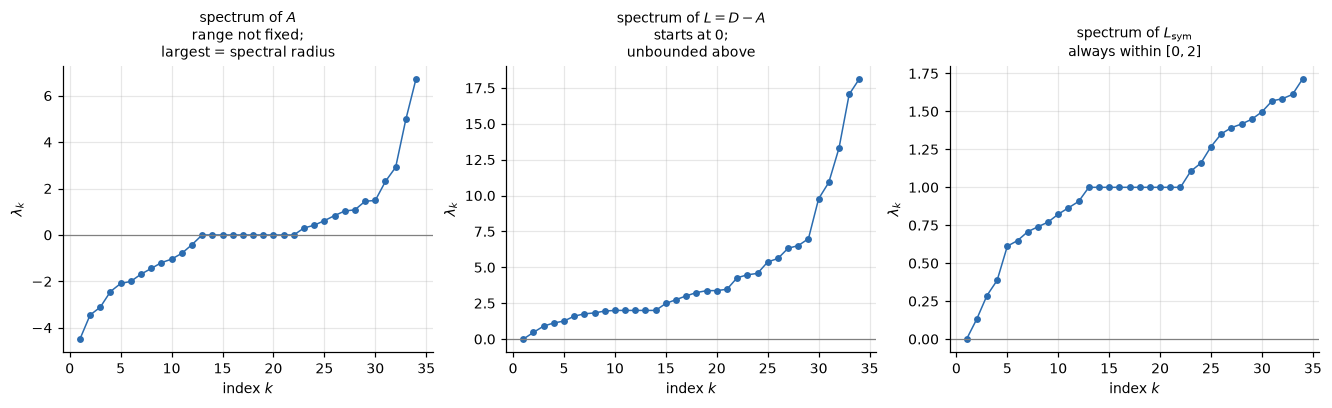

                              min   2nd smallest        max
A  (adjacency)            -4.4872        -3.4479     6.7257
L  (combinatorial)         0.0000         0.4685    18.1367
L_sym (normalised)         0.0000         0.1323     1.7146


In [27]:
lam_A = np.linalg.eigvalsh(A)           # adjacency spectrum, for comparison

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (spec, name, note) in zip(axes, [
        (lam_A, "$A$", "range not fixed;\nlargest = spectral radius"),
        (lam, "$L = D - A$", "starts at 0;\nunbounded above"),
        (lam_sym, "$L_{\\mathrm{sym}}$", "always within $[0, 2]$")]):
    ax.plot(np.arange(1, n + 1), spec, "o-", ms=3.5, lw=1, color="#2b6cb0")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(f"spectrum of {name}\n{note}", fontsize=9)
    ax.set_xlabel("index $k$")
    ax.set_ylabel(r"$\lambda_k$")
plt.show()

print(f"{'':22s} {'min':>10s} {'2nd smallest':>14s} {'max':>10s}")
for name, spec in [("A  (adjacency)", lam_A), ("L  (combinatorial)", lam), ("L_sym (normalised)", lam_sym)]:
    print(f"{name:22s} {spec[0]:10.4f} {spec[1]:14.4f} {spec[-1]:10.4f}")

**The three spectra are not interchangeable — they answer different questions.**

| Matrix | Smallest eigenvalues mean | Largest eigenvalue means | Typical use |
|---|---|---|---|
| $A$ | little directly | spectral radius $\lambda_{\max}(A)$: growth rate of walk counts; its eigenvector is **eigenvector centrality** | centrality, counting walks, epidemic thresholds |
| $L=D-A$ | multiplicity of 0 = components; $\lambda_2$ = algebraic connectivity | roughest pattern; $\lambda_{\max} \ge d_{\max}+1$ | connectivity, bottlenecks, unnormalised cuts |
| $L_{\mathrm{sym}}$ | same component count; $\lambda_2$ = degree-normalised connectivity | $\le 2$, with equality **iff** a component is bipartite | clustering on degree-heterogeneous graphs |

A concrete trap: "the second eigenvalue" means algebraic connectivity for $L$, but for $A$ the
second-*largest* eigenvalue is about expansion and mixing — a different quantity with a different
sign convention and a different sort order. Always say which matrix you mean.

The bipartite fact is worth seeing, since it is an exact "iff" rather than a heuristic.

In [28]:
for name, g in [("complete bipartite K_{3,4}", nx.complete_bipartite_graph(3, 4)),
                ("6-cycle (bipartite)", nx.cycle_graph(6)),
                ("5-cycle (odd, not bipartite)", nx.cycle_graph(5)),
                ("karate club", G)]:
    nl_ = sorted(g.nodes())
    A_ = nx.to_numpy_array(g, nodelist=nl_, weight=None)
    d_ = A_.sum(axis=1)
    s_ = np.zeros_like(d_); s_[d_ > 0] = 1.0 / np.sqrt(d_[d_ > 0])
    top = np.linalg.eigvalsh(np.eye(len(nl_)) - np.diag(s_) @ A_ @ np.diag(s_))[-1]
    print(f"{name:30s} lambda_max(L_sym) = {top:.6f}   bipartite: {nx.is_bipartite(g)}")

complete bipartite K_{3,4}     lambda_max(L_sym) = 2.000000   bipartite: True
6-cycle (bipartite)            lambda_max(L_sym) = 2.000000   bipartite: True
5-cycle (odd, not bipartite)   lambda_max(L_sym) = 1.809017   bipartite: False
karate club                    lambda_max(L_sym) = 1.714611   bipartite: False


### Three things that are easy to get wrong

**1. Eigenvector signs are arbitrary.** If $Lu = \lambda u$ then $L(-u) = \lambda(-u)$, so $-u$
is an equally valid eigenvector. `eigh` picks one, and the choice depends on the LAPACK build and
even on the node ordering. Never interpret "positive side" as meaningful in itself — only the
*partition* into two sides is meaningful, which is why Section 4 scored both alignments.

**2. Repeated eigenvalues make individual eigenvectors ambiguous.** If $\lambda$ appears with
multiplicity $m>1$, the solutions of $Lu=\lambda u$ form an $m$-dimensional subspace, and *any*
orthonormal basis of it is a legitimate set of eigenvectors. The individual vectors a solver
returns are then an arbitrary choice; only the subspace is determined. Symmetric graphs are full
of such repeats.

**3. The spectrum does not determine the graph.** Two non-isomorphic graphs can share a spectrum
("cospectral" graphs). The spectrum is a genuine invariant — different spectra prove
non-isomorphism — but a matching spectrum proves nothing.

In [29]:
# (1) Sign arbitrariness -- the same graph, nodes relabelled, gives a flipped u_2.
perm = rng.permutation(n)
G_relab = nx.relabel_nodes(G, {nodelist[i]: int(perm[i]) for i in range(n)})
A_relab = nx.to_numpy_array(G_relab, nodelist=sorted(G_relab.nodes()), weight=None)
lam_relab, U_relab = np.linalg.eigh(np.diag(A_relab.sum(axis=1)) - A_relab)

u2_relab = U_relab[:, 1][perm]
print("relabelled graph: spectrum identical:", np.allclose(lam, lam_relab))
print(f"u_2 recovered as-is  : max |difference| = {np.abs(u2_relab - fiedler).max():.2e}")
print(f"u_2 recovered negated: max |difference| = {np.abs(-u2_relab - fiedler).max():.2e}")
print("-> one of these is ~0: the vector is the same up to an arbitrary global sign.")
print()

# (2) Repeated eigenvalues -- the 6-cycle has two-dimensional eigenspaces.
C6 = nx.cycle_graph(6)
A6 = nx.to_numpy_array(C6, nodelist=sorted(C6.nodes()), weight=None)
L6 = np.diag(A6.sum(axis=1)) - A6
lam6, U6 = np.linalg.eigh(L6)
print("6-cycle spectrum:", np.round(lam6, 6), " <- 1 and 3 each appear twice")

v1, v2 = U6[:, 1], U6[:, 2]                 # a basis of the lambda = 1 eigenspace
theta = 0.7
w1 = np.cos(theta) * v1 + np.sin(theta) * v2      # an arbitrary rotation within that eigenspace
w2 = -np.sin(theta) * v1 + np.cos(theta) * v2
print(f"rotated pair still orthonormal    : {abs(w1 @ w2) < 1e-12}, {abs(np.linalg.norm(w1) - 1) < 1e-12}")
print(f"rotated pair still eigenvectors   : {np.allclose(L6 @ w1, lam6[1] * w1)}, "
      f"{np.allclose(L6 @ w2, lam6[2] * w2)}")
print("-> the solver's choice within a repeated eigenspace is arbitrary; only the subspace is fixed.")

relabelled graph: spectrum identical: True
u_2 recovered as-is  : max |difference| = 2.55e-15
u_2 recovered negated: max |difference| = 8.46e-01
-> one of these is ~0: the vector is the same up to an arbitrary global sign.

6-cycle spectrum: [-0.  1.  1.  3.  3.  4.]  <- 1 and 3 each appear twice
rotated pair still orthonormal    : True, True
rotated pair still eigenvectors   : True, True
-> the solver's choice within a repeated eigenspace is arbitrary; only the subspace is fixed.


Cospectral with respect to A (the classic smallest example):
  K_{1,4}        A-spectrum [-2.  0.  0.  0.  2.]   L-spectrum [0. 1. 1. 1. 5.]
  C_4 + isolated  A-spectrum [-2. -0.  0.  0.  2.]   L-spectrum [-0.  0.  2.  2.  4.]
  isomorphic? False  <- identical A-spectra, different graphs
  (here the L-spectra differ, which does distinguish them)

Cospectral with respect to L (6 nodes, 7 edges, both connected):
  H1  L-spectrum [-0.      0.7639  2.      3.      3.      5.2361]   degree sequence [1, 2, 2, 3, 3, 3]
  H2  L-spectrum [-0.      0.7639  2.      3.      3.      5.2361]   degree sequence [2, 2, 2, 2, 2, 4]
  isomorphic? False  <- identical L-spectra, different degree sequences


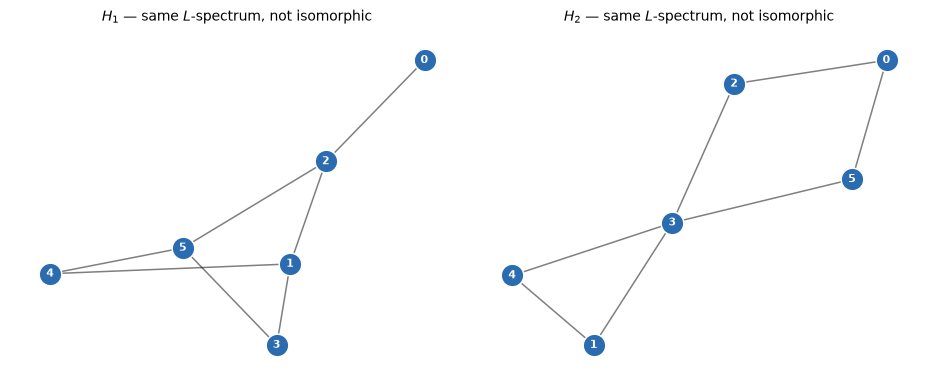

In [30]:
# (3) Cospectral graphs: same spectrum, different graph.
star = nx.star_graph(4)                                        # K_{1,4}
c4k1 = nx.disjoint_union(nx.cycle_graph(4), nx.empty_graph(1))  # C_4 plus an isolated node

def spectra(g):
    A_ = nx.to_numpy_array(g, nodelist=sorted(g.nodes()), weight=None)
    return (np.round(np.linalg.eigvalsh(A_), 4),
            np.round(np.linalg.eigvalsh(np.diag(A_.sum(axis=1)) - A_), 4))

print("Cospectral with respect to A (the classic smallest example):")
for name, g in [("K_{1,4}      ", star), ("C_4 + isolated", c4k1)]:
    sa, sl = spectra(g)
    print(f"  {name}  A-spectrum {sa}   L-spectrum {sl}")
print(f"  isomorphic? {nx.is_isomorphic(star, c4k1)}  <- identical A-spectra, different graphs")
print("  (here the L-spectra differ, which does distinguish them)")
print()

# A pair that is cospectral for L as well -- found by exhaustive search over small graphs.
H1 = nx.Graph([(0, 2), (1, 2), (1, 3), (1, 4), (2, 5), (3, 5), (4, 5)])
H2 = nx.Graph([(0, 2), (0, 5), (1, 3), (1, 4), (2, 3), (3, 4), (3, 5)])
print("Cospectral with respect to L (6 nodes, 7 edges, both connected):")
for name, g in [("H1", H1), ("H2", H2)]:
    print(f"  {name}  L-spectrum {spectra(g)[1]}   degree sequence "
          f"{sorted(dd for _, dd in g.degree())}")
print(f"  isomorphic? {nx.is_isomorphic(H1, H2)}  <- identical L-spectra, different degree sequences")

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.4))
for ax, (name, g) in zip(axes, [("$H_1$", H1), ("$H_2$", H2)]):
    p = nx.spring_layout(g, seed=3)
    nx.draw_networkx_edges(g, p, ax=ax, alpha=0.5)
    nx.draw_networkx_nodes(g, p, ax=ax, node_color="#2b6cb0", node_size=220,
                           edgecolors="white", linewidths=1.0)
    nx.draw_networkx_labels(g, p, ax=ax, font_size=7, font_color="white", font_weight="bold")
    ax.set_title(f"{name} — same $L$-spectrum, not isomorphic", fontsize=9)
    ax.set_axis_off(); ax.grid(False)
plt.show()

$H_1$ and $H_2$ have the same Laplacian spectrum yet different degree sequences, so they cannot
be isomorphic. The lesson: **the spectrum is a summary, not a fingerprint.** It answers questions
about connectivity and separability — the ones this lesson posed — but it discards information,
and no amount of spectral data will reconstruct the graph in general.

> 📖 **Reference — choosing the operator.**
> [von Luxburg (2007)](https://arxiv.org/abs/0711.0189), Section 8 ("Which graph Laplacian should
> be used?"). Read it for the concrete recommendation and its justification: on graphs with
> broadly varying degrees, prefer a normalised Laplacian, because unnormalised spectral
> clustering can fail to converge to a sensible partition and tends to cut off small groups of
> low-degree nodes.

---
## 6. Recap and verification

### What the spectrum told us

| Spectral quantity | Structural meaning | Value here |
|---|---|---|
| $\lambda_k \ge 0$ for all $k$ | $L$ is positive semidefinite ($q^\top L q$ is a sum of squares) | spectrum in $[0, 18.14]$ |
| $\#\{k:\lambda_k = 0\}$ | number of connected components | $1$ — the graph is connected |
| $\lambda_2$ (algebraic connectivity) | how hard the graph is to disconnect | $0.469$ — **45% of the ceiling** $\tfrac{n}{n-1}d_{\min}=1.03$, not near zero |
| $\lambda_2$ vs. rewiring null | is the *arrangement* of edges unusual? | more splittable than $\approx 90\%$ of degree-preserving rewirings |
| $\operatorname{sign}(u_2)$ | the cheapest near-balanced cut | recovers the historical split for $32/34$ members — **tied** by Girvan–Newman and greedy modularity |
| $|u_2(i)|$ small | node $i$ is structurally ambiguous | exactly the members the cut misplaces |
| $(u_2, u_3)$ | coordinates from connectivity alone | $u_2$ separates factions; $u_3$ is localised on pendant nodes |
| $\lambda_k = u_k^\top L u_k$ | graph frequency of pattern $u_k$ | $0$ (constant) up to $18.14$ (hub oscillation) |
| $q^\top Lq = \lVert\nabla q\rVert^2$ | Dirichlet energy = squared discrete gradient | the quantity every eigenvector minimises, in turn |

And the distinction to carry forward: **everything above is a property of the graph.** The
eigenvectors are patterns the graph defines. The moment you also have a measured signal
$x \in \mathbb{R}^n$, projecting it onto this basis — $\hat{x} = U^\top x$ — gives the **graph
Fourier transform**, which describes the *data*, not the domain. Same basis, different object.

### Check your understanding

<details>
<summary><b>1.</b> A colleague computes the Laplacian spectrum of a 500-node network and finds
the four smallest eigenvalues are 0, 0, 0, and 0.002. What do you tell them?</summary>

The graph has **three** connected components (three exact zeros), and one of those components is
itself nearly split in two — $\lambda_4 = 0.002$ is the algebraic connectivity of the
best-connected structure remaining, and it is very close to zero. Practically: run the component
decomposition first, then look for a bottleneck inside the largest piece. Beware also that "zero"
means "below a tolerance"; with 500 nodes, decide the tolerance deliberately rather than testing
`== 0`.
</details>

<details>
<summary><b>2.</b> You rerun your analysis on a different machine and every entry of the Fiedler
vector has flipped sign. Is the result wrong?</summary>

No. If $Lu_2 = \lambda_2 u_2$ then $-u_2$ is an equally valid eigenvector, and which one a solver
returns depends on the LAPACK implementation. The *partition* — which nodes share a sign — is
unchanged, and that is the only thing the method claims. Any downstream code must be invariant to
this, for example by scoring both alignments (as Section 4 does) or by fixing a convention such as
"the entry of largest magnitude is positive".
</details>

<details>
<summary><b>3.</b> Why exclude the constant vector when minimising $q^\top L q$, and why require
$\|q\| = 1$?</summary>

Without $q^\top\mathbf{1}=0$ the minimum is attained by the constant vector with energy exactly
$0$, which says only "the graph is connected" and identifies no cut. Without $\|q\|=1$ we could
shrink any $q$ towards $0$ and drive the energy arbitrarily low without changing its shape. The
two constraints together force $q$ to be a genuinely varying, fixed-size pattern, and the cheapest
such pattern is the one that changes value where the edges are sparsest.
</details>

<details>
<summary><b>4.</b> Two graphs have identical Laplacian spectra. Are they the same graph?</summary>

Not necessarily — see $H_1$ and $H_2$ in Section 5, which have identical $L$-spectra and different
degree sequences. The implication runs one way only: *different* spectra prove the graphs are not
isomorphic, but identical spectra prove nothing. The spectrum is a lossy summary.
</details>

<details>
<summary><b>5.</b> Your graph has degrees ranging from 2 to 4000, and the sign of $u_2$ of $L$
splits off a single node. What happened, and what would you try?</summary>

Unnormalised $L$ charges Dirichlet energy per edge, so the cheapest cut is often to isolate one
low-degree node rather than to find a balanced partition — with extreme degree heterogeneity that
is genuinely the minimum, just not the answer you wanted. Switch to $L_{\mathrm{sym}}$ (or the
random-walk Laplacian $L_{\mathrm{rw}} = D^{-1}L$), which divides each node's contribution by its
degree; von Luxburg's Section 8 recommends exactly this. Section 5 shows this failure happening
on the karate club itself: $u_3$ of $L$ is localised on a degree-1 node, and $k$-means on the
unnormalised embedding cuts that node off instead of finding the factions. Row-normalising the
$L_{\mathrm{sym}}$ eigenvectors repairs it.
</details>

<details>
<summary><b>6.</b> Someone colours a graph by $u_3$ and describes it as "the data on the network".
What is the error?</summary>

$u_3$ is not data. It was computed from $L$, which was computed from the edge set; no measurement
entered anywhere. It is a pattern the graph defines about itself. Data would be a separate vector
$x\in\mathbb{R}^n$ of measured values, and its graph Fourier coefficients $\hat{x}_k = u_k^\top x$
would describe how that measurement distributes across the graph's frequencies. Confusing the
basis with a signal expanded in it is the central confusion this lesson exists to prevent.
</details>

<details>
<summary><b>7.</b> You compute $\lambda_2 = 0.03$ on a 200-node network and write "the network is
nearly disconnected". What should you check before that sentence survives review?</summary>

Whether $0.03$ is small *for this graph*. Three checks, all demonstrated in Section 4. First the
ceiling $\lambda_2 \le \tfrac{n}{n-1}d_{\min}$: if any node has degree 1, $\lambda_2$ cannot
exceed about $1$, so $0.03$ is being read against a scale the graph could never reach. Second a
reference graph of the same size — a 200-node path has $\lambda_2 \approx 2.5\times10^{-4}$, two
orders of magnitude below yours, so you are nowhere near genuinely stringy. Third a
degree-preserving rewiring ensemble, which isolates the only question that is really about
structure: is this graph easier to split than its degree sequence alone predicts? On the karate
club the ceiling turns out to be the binding constraint, and the intuitive reading of
$\lambda_2 = 0.469$ is wrong.
</details>

<details>
<summary><b>8.</b> Two colleagues compute Dirichlet energies of two patterns on the same graph.
One reports $q^\top L q = 4.1$, the other $312.7$, and the second concludes their pattern is far
rougher. Are they right?</summary>

Not on that evidence. Dirichlet energy scales as $\lVert q\rVert^2$, so a vector ten times longer
carries one hundred times the energy with exactly the same shape. The comparable quantity is the
Rayleigh quotient $\mathcal{R}(q) = q^\top L q / q^\top q$, which is invariant to rescaling.
Normalise both vectors, or compare Rayleigh quotients, before saying anything about roughness.
This is precisely why the eigenvalues in this lesson are read off **unit** eigenvectors: when
$\lVert u_k\rVert = 1$ the two measures coincide and $\lambda_k$ is unambiguously both.
</details>

### Correctness checks

Every claim above rests on properties we should verify rather than trust.

In [31]:
tol = 1e-9
checks = []

def check(name, ok, detail=""):
    checks.append((name, bool(ok), detail))

# --- structural assumptions ---------------------------------------------------
check("A is symmetric", np.allclose(A, A.T, atol=tol))
check("A is 0/1 with zero diagonal",
      set(np.unique(A)) <= {0.0, 1.0} and np.allclose(np.diag(A), 0))
check("L is symmetric", np.allclose(L, L.T, atol=tol),
      f"max |L - L^T| = {np.abs(L - L.T).max():.2e}")
check("L = D - A exactly", np.allclose(L, np.diag(d) - A, atol=tol))

# --- L annihilates the constant vector ----------------------------------------
res_const = np.abs(L @ np.ones(n)).max()
check("L @ 1 == 0", res_const < tol, f"max |L @ 1| = {res_const:.2e}")

# --- eigendecomposition -------------------------------------------------------
check("eigenvalues sorted increasingly", np.all(np.diff(lam) >= -tol))
check("eigenvalues are non-negative (L is PSD)", lam.min() > -tol,
      f"min lambda = {lam.min():.2e}")

recon = np.abs(U @ np.diag(lam) @ U.T - L).max()
check("L == U @ diag(lambda) @ U^T", recon < 1e-9, f"max |error| = {recon:.2e}")

orth = np.abs(U.T @ U - np.eye(n)).max()
check("U^T U == I (orthonormal eigenvectors)", orth < 1e-9, f"max |error| = {orth:.2e}")

eig_res = max(np.abs(L @ U[:, k] - lam[k] * U[:, k]).max() for k in range(n))
check("L u_k == lambda_k u_k for every k", eig_res < 1e-9, f"max residual = {eig_res:.2e}")

# --- the quadratic form -------------------------------------------------------
qf_err = max(abs(U[:, k] @ L @ U[:, k] - lam[k]) for k in range(n))
check("u_k^T L u_k == lambda_k", qf_err < 1e-9, f"max |error| = {qf_err:.2e}")

q_rand = rng.standard_normal(n)
check("q^T L q == sum over edges of (q_i - q_j)^2",
      np.isclose(q_rand @ L @ q_rand, dirichlet_energy(q_rand)))

# --- zero eigenvalues count the components ------------------------------------
n_zero = int(np.sum(np.abs(lam) < 1e-8))
n_comp = nx.number_connected_components(G)
check("#{k : lambda_k == 0} == number of components", n_zero == n_comp,
      f"{n_zero} zeros vs {n_comp} components")

# the same identity on a graph deliberately built with several components
n_zero_H = int(np.sum(np.abs(lam_H) < 1e-8))
check("same identity on the 3-component test graph",
      n_zero_H == nx.number_connected_components(H),
      f"{n_zero_H} zeros vs {nx.number_connected_components(H)} components")

# --- trace identity -----------------------------------------------------------
check("sum of eigenvalues == trace(L) == 2|E|",
      np.isclose(lam.sum(), 2 * G.number_of_edges()) and np.isclose(np.trace(L), lam.sum()))

# --- normalised Laplacian -----------------------------------------------------
check("L_sym is symmetric", np.allclose(L_sym, L_sym.T, atol=tol))
check("L_sym spectrum lies in [0, 2]", lam_sym.min() > -tol and lam_sym.max() < 2 + tol,
      f"[{lam_sym[0]:.4f}, {lam_sym[-1]:.4f}]")
check("L_sym has the same component count",
      int(np.sum(np.abs(lam_sym) < 1e-8)) == n_comp)

# --- the Fiedler vector -------------------------------------------------------
check("u_2 is orthogonal to the constant vector", abs(fiedler.sum()) < 1e-9,
      f"sum = {fiedler.sum():.2e}")
check("u_2 has unit norm", np.isclose(np.linalg.norm(fiedler), 1.0))
check("both signs present in u_2", (fiedler > 0).any() and (fiedler < 0).any())
check("Fiedler partition recovers most of the historical split", accuracy > 0.9,
      f"accuracy = {accuracy:.1%}")

# --- the gradient factorisation and the two indexing conventions --------------
grad_err = np.abs(L - Nabla.T @ Nabla).max()
check("L == Nabla^T Nabla (gradient factorisation)", grad_err < tol,
      f"max |error| = {grad_err:.2e}")

q_chk = rng.standard_normal(n)
check("edge sum == (1/2) * ordered-pair sum",
      np.isclose(dirichlet_energy(q_chk),
                 0.5 * sum(A[i, j] * (q_chk[i] - q_chk[j]) ** 2
                           for i in range(n) for j in range(n))))
check("q^T L q == ||grad q||^2",
      np.isclose(q_chk @ L @ q_chk, np.linalg.norm(Nabla @ q_chk) ** 2))
check("Rayleigh quotient is invariant to rescaling q",
      np.isclose(rayleigh(q_chk), rayleigh(7.5 * q_chk)),
      f"R(q) = {rayleigh(q_chk):.6f}, R(7.5q) = {rayleigh(7.5 * q_chk):.6f}")

# --- calibration of lambda_2 --------------------------------------------------
check("lambda_2 respects the bound n/(n-1) * d_min", lam[1] <= n / (n - 1) * d.min() + tol,
      f"{lam[1]:.4f} <= {n / (n - 1) * d.min():.4f}")
check("rewiring null preserved every degree",
      sorted(dd for _, dd in null_example.degree()) == sorted(dd for _, dd in G.degree()))
check("rewiring null actually changed the edge set",
      set(map(frozenset, null_example.edges())) != set(map(frozenset, G.edges())))
check("null ensemble large enough to quote a percentage", len(null_lam2) >= 400,
      f"{len(null_lam2)} connected rewirings")

# --- report -------------------------------------------------------------------
width = max(len(name) for name, _, _ in checks)
for name, ok, detail in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {name:<{width}}  {detail}")

failed = [name for name, ok, _ in checks if not ok]
assert not failed, f"failed checks: {failed}"
print(f"\nAll {len(checks)} checks passed.")

PASS  A is symmetric                                           
PASS  A is 0/1 with zero diagonal                              
PASS  L is symmetric                                           max |L - L^T| = 0.00e+00
PASS  L = D - A exactly                                        
PASS  L @ 1 == 0                                               max |L @ 1| = 0.00e+00
PASS  eigenvalues sorted increasingly                          
PASS  eigenvalues are non-negative (L is PSD)                  min lambda = 2.49e-16
PASS  L == U @ diag(lambda) @ U^T                              max |error| = 2.49e-14
PASS  U^T U == I (orthonormal eigenvectors)                    max |error| = 1.89e-15
PASS  L u_k == lambda_k u_k for every k                        max residual = 1.60e-14
PASS  u_k^T L u_k == lambda_k                                  max |error| = 2.84e-14
PASS  q^T L q == sum over edges of (q_i - q_j)^2               
PASS  #{k : lambda_k == 0} == number of components             1 zeros vs 1 

---
## Appendix — scaling up (optional, no download required)

The karate club is small enough to reason about node by node. The same code applies unchanged to
larger graphs, where the spectrum stops being a curiosity and becomes the only practical way to
see the structure.

> 📖 **Reference — a larger application.**
> [SNAP `email-Eu-core`](https://snap.stanford.edu/data/email-Eu-core.html): 1005 members of a
> European research institution, an edge whenever one person emailed another, plus each person's
> real department as ground truth. Read it as the natural next test of this lesson's method —
> it has 42 departments instead of 2 factions, so it exercises $k$-way spectral clustering rather
> than a single Fiedler cut, and the department labels let you score the result the same way we
> scored the club split.

**The core lesson runs without this file.** The cell below looks for the dataset locally and
explains what to do if it is absent; nothing later depends on it.

Two preprocessing steps are mandatory for that dataset, because the raw file does not satisfy
this lesson's assumptions:

1. **Symmetrisation.** The raw edges are *directed* (`u` emailed `v`). Everything here requires
   $A=A^\top$. Reading the file into an undirected `nx.Graph` symmetrises it by construction —
   equivalent to replacing $A$ with $\max(A, A^\top)$, i.e. an edge whenever email flowed in
   *either* direction. Note this is a modelling decision, not a formality: it treats a single
   unanswered email the same as a long correspondence.
2. **Self-loop removal.** People email themselves, producing entries $A_{ii}=1$. A self-loop adds
   $1$ to $d_i$ *and* $1$ to $A_{ii}$, so it cancels in $L = D - A$ and leaves the Laplacian
   unchanged — but it does change $A$, so any adjacency-based quantity (degree, centrality) would
   be silently off. Remove them explicitly.

You would also want `scipy.sparse.linalg.eigsh(..., k=..., sigma=0)` rather than dense `eigh`:
at $n = 1005$ a dense decomposition is fine, but it costs $O(n^3)$ and you normally need only the
few smallest eigenpairs.

In [32]:
import os
import scipy.sparse as sp
import scipy.sparse.linalg as spla

EMAIL_PATH = "email-Eu-core.txt"        # from https://snap.stanford.edu/data/email-Eu-core.html

if not os.path.exists(EMAIL_PATH):
    print(f"'{EMAIL_PATH}' not found -- skipping the optional example.")
    print("To run it: download email-Eu-core.txt.gz from")
    print("  https://snap.stanford.edu/data/email-Eu-core.html")
    print("unzip it next to this notebook, and re-run this cell.")
    print("Nothing else in the lesson depends on it.")
else:
    # nx.Graph (undirected) symmetrises the directed edge list as it reads.
    G_email = nx.read_edgelist(EMAIL_PATH, nodetype=int, create_using=nx.Graph)
    G_email.remove_edges_from(nx.selfloop_edges(G_email))      # drop self-emails

    email_nodes = sorted(G_email.nodes())
    A_e = nx.to_scipy_sparse_array(G_email, nodelist=email_nodes, weight=None, format="csr")
    d_e = np.asarray(A_e.sum(axis=1)).ravel()
    L_e = sp.diags(d_e) - A_e

    print(f"nodes {G_email.number_of_nodes()}, edges {G_email.number_of_edges()}, "
          f"components {nx.number_connected_components(G_email)}")
    print(f"symmetric: {(abs(A_e - A_e.T)).nnz == 0}, self-loops: {A_e.diagonal().sum():.0f}")

    # Only the 6 smallest eigenpairs, via a sparse shift-invert solver.
    vals, vecs = spla.eigsh(L_e.asfptype(), k=6, sigma=0, which="LM")
    idx = np.argsort(vals)
    vals, vecs = vals[idx], vecs[:, idx]
    print("six smallest eigenvalues:", np.round(vals, 6))
    print(f"zero eigenvalues: {int(np.sum(np.abs(vals) < 1e-8))} "
          f"== components {nx.number_connected_components(G_email)}")

'email-Eu-core.txt' not found -- skipping the optional example.
To run it: download email-Eu-core.txt.gz from
  https://snap.stanford.edu/data/email-Eu-core.html
unzip it next to this notebook, and re-run this cell.
Nothing else in the lesson depends on it.


---
## Where to go next

You now have the graph's own coordinate system: an orthonormal basis $U$ ordered by a
well-defined notion of frequency, built from nothing but the edge set. The natural continuation
is to put **data** on the graph and expand it in this basis — $\hat{x}=U^\top x$, the graph
Fourier transform — which turns filtering, smoothing, and denoising on networks into
multiplication by a function of $\lambda$, exactly as on the real line.

Two threads from this lesson continue directly. The **Dirichlet energy** $x^\top L x$, which
here was a sum over edges, acquires a second form the moment a signal exists:

$$x^\top L x \;=\; \sum_{k=1}^{n} \lambda_k\,|\hat{x}_k|^2 ,$$

resolving a single roughness number into a contribution from each graph frequency — the same
quantity, read through the transform. And the **null-model habit** from Section 4 flips over:
instead of rewiring the graph, hold it fixed and permute a measured signal across its nodes,
which tests whether the *data* is smooth on this structure rather than whether the structure
itself is unusual.

### References collected

- **[`networkx.karate_club_graph()`](https://networkx.org/documentation/stable/reference/generated/networkx.generators.social.karate_club_graph.html)**
  — what the nodes and edges of our example actually record, and the citation to Zachary (1977).
- **[von Luxburg, *A Tutorial on Spectral Clustering* (2007)](https://arxiv.org/abs/0711.0189)**
  — the main reference for this lesson: Laplacian properties (§3), the cut relaxation that
  justifies the Fiedler partition (§5), and which Laplacian to choose (§8).
- **[Shuman et al., *The Emerging Field of Signal Processing on Graphs* (2013)](https://arxiv.org/abs/1211.0053)**
  — the graph-frequency interpretation of $\lambda_k$ and the definition of the GFT; the direct
  bridge to the next lesson.
- **[SNAP `email-Eu-core`](https://snap.stanford.edu/data/email-Eu-core.html)** — a 1005-node
  network with departmental ground truth, for practising $k$-way spectral clustering at a scale
  where you cannot check the answer by eye.